# Оператор связи «ТелеДом»

# Предсказание прекращения абонентского договора

Оператор связи «ТелеДом» хочет бороться с оттоком клиентов. Для этого его сотрудники начнут предлагать промокоды и специальные условия всем, кто планирует отказаться от услуг связи. Чтобы заранее находить таких пользователей, «ТелеДому» требуется модель, которая будет предсказывать, разорвёт ли абонент договор.

Команда оператора собрала персональные данные о некоторых клиентах, информацию об их тарифах и услугах. Ваша задача — обучить на этих данных модель для прогноза оттока клиентов.

Оператор предоставляет два основных типа услуг:
1. Стационарную телефонную связь. Телефон можно подключить к нескольким линиям одновременно.
2. Интернет. Подключение бывает двух типов: через телефонную линию DSL (англ. digital subscriber line — «цифровая абонентская линия») или оптоволоконный кабель (англ. fiber optic). Также абонентам доступен ряд услуг: интернет-безопасность - антивирус, блокировка опасных сайтов, выделенная линия технической поддержки, облачное хранилище файлов для резервного копирования данных, стриминговое телевидение, каталог фильмов.

За услуги клиенты могут платить ежемесячно или раз в 1–2 года.

Доступны различные способы расчёта и возможность получить электронный чек.

Данные хранятся в Sqlite  — СУБД, в которой база данных представлена одним файлом. Она состоит из нескольких таблиц:
- contract — информация о договорах;
- personal — персональные данные клиентов;
- internet — информация об интернет-услугах;
- phone — информация об услугах телефонии.

**Установки и импорты:**

In [1]:
pip install phik -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install lightgbm -q

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn -q

Note: you may need to restart the kernel to use updated packages.


In [4]:
import sqlite3

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)

import phik
from phik import report

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, accuracy_score, confusion_matrix, precision_recall_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

import lightgbm as lgb
from catboost import CatBoostClassifier
from catboost import Pool

RANDOM_STATE = 121026

## Загрузка данных

**Подключимся к базе данных:**

In [5]:
path_to_db = 'ds-plus-final.db'
engine = sqlite3.connect(path_to_db)

In [6]:
query_tables = """
SELECT name 
FROM sqlite_master 
WHERE type='table' 
ORDER BY name;
"""

pd.read_sql_query(query_tables, con=engine)

,name
0,contract
1,data_arc
2,data_bulk
3,data_bulk_time
4,data_gas
5,data_temp
6,data_wire
7,data_wire_time
8,internet
9,personal


In [7]:
tables = ['contract', 'personal', 'internet', 'phone']

for table in tables:
    query = f"SELECT * FROM {table} LIMIT 3"
    display(table)
    display(pd.read_sql_query(query, con=engine))
    display('---------------------------------')

'contract'

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,31.04
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,2071.84
2,3668-QPYBK,2019-10-01,No,Month-to-month,Yes,Mailed check,53.85,226.17


'---------------------------------'

'personal'

,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No


...

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No


'---------------------------------'

'phone'

,CustomerId,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No


'---------------------------------'

**Необходимые таблицы присутствуют в базе данных, содержат соответствующую информацию.**

In [8]:
query_counts = """
SELECT 'contract' AS table_name, COUNT(*) AS row_count FROM contract
UNION ALL
SELECT 'personal', COUNT(*) FROM personal
UNION ALL
SELECT 'internet', COUNT(*) FROM internet
UNION ALL
SELECT 'phone', COUNT(*) FROM phone;
"""

pd.read_sql_query(query_counts, con=engine)

,table_name,row_count
0,contract,7043
1,personal,7043
2,internet,5517
3,phone,6361


**Объем таблиц небольшой. Поэтому для исследовательского анализа позволим себе выгрузить таблицы полностью.**

## Исследовательский анализ и предобработка данных

### contract
- customer_id — ID абонента;
- begin-date — дата начала действия договора;
- end_date — дата окончания действия договора;
- type — тип оплаты: раз в год-два или ежемесячно;
- paperless_billing — электронный расчётный лист;
- payment_method — тип платежа;
- monthly_charges — расходы за месяц;
- total_charges — общие расходы абонента.

Сначала осмотрим информацию о таблице внутри базы данных. Затем выгрузим её, сразу приведем наименования столбцов к змеиному виду.

In [9]:
table_name = "contract" 
query = f"PRAGMA table_info({table_name})"
pd.read_sql_query(query, con=engine)

,cid,name,type,notnull,dflt_value,pk
0,0,customerID,TEXT,0,None,0
1,1,BeginDate,TEXT,0,None,0
2,2,EndDate,TEXT,0,None,0
3,3,Type,TEXT,0,None,0
4,4,PaperlessBilling,TEXT,0,None,0
5,5,PaymentMethod,TEXT,0,None,0
6,6,MonthlyCharges,TEXT,0,None,0
7,7,TotalCharges,TEXT,0,None,0


In [10]:
contract = pd.read_sql_query("SELECT * FROM contract;", con=engine)

In [11]:
contract.columns = contract.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True).str.lower()

contract.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        7043 non-null   object
 1   begin_date         7043 non-null   object
 2   end_date           7043 non-null   object
 3   type               7043 non-null   object
 4   paperless_billing  7043 non-null   object
 5   payment_method     7043 non-null   object
 6   monthly_charges    7043 non-null   object
 7   total_charges      7043 non-null   object
dtypes: object(8)
memory usage: 440.3+ KB


In [12]:
contract.duplicated().sum()

0

Пропуски и дубликаты отсутствуют. Все данные сохранены в типе object, что некорректно.

#### customer_id

In [13]:
contract['customer_id'].nunique()

7043

7043 уникальных id абонентов.

#### begin_date

Приведем столбец к корректному типу:

In [14]:
contract['begin_date'] = pd.to_datetime(contract['begin_date'])

In [15]:
contract['begin_date'].describe()

count                             7043
mean     2017-04-30 13:01:50.918642688
min                2013-10-01 00:00:00
25%                2015-06-01 00:00:00
50%                2017-09-01 00:00:00
75%                2019-04-01 00:00:00
max                2020-02-01 00:00:00
Name: begin_date, dtype: object

In [16]:
contract['begin_date'].dt.year.sort_values().unique()

array([2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020])

In [17]:
contract['begin_date'].dt.month.sort_values().unique()

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12])

In [18]:
contract['begin_date'].dt.day.sort_values().unique()

array([1])

In [19]:
contract['begin_date'].drop_duplicates().sort_values()

3439   2013-10-01
975    2013-11-01
5441   2013-12-01
1306   2014-01-01
28     2014-02-01
          ...    
2      2019-10-01
20     2019-11-01
31     2019-12-01
0      2020-01-01
488    2020-02-01
Name: begin_date, Length: 77, dtype: datetime64[ns]

Зафиксированы месяцы заключения договоров.

Интервал наблюдения - с октября 2013 г. по 01.02.2020 (на эту дату собраны данные).

В анализируемом периоде договоры заключались каждый месяц.

In [20]:
contract[contract['begin_date'] == pd.Timestamp('2020-02-01')]['begin_date'].count()

11

In [21]:
contract[contract['begin_date'] == pd.Timestamp('2020-01-01')]['begin_date'].count()

233

In [22]:
contract[contract['begin_date'] == pd.Timestamp('2019-12-01')]['begin_date'].count()

220

Договоров с датой 01.02.2020 - 11. Скорее всего, это договоры, заключенные за 1 день, в который сделана выгрузка. В таком случае эти строки не представляют собой наблюдения за поведением абонента (расторгнут ли договор, на каком сроке, или открыт), и их можно удалить.

Но возможен и вариант, что данные приведены помесячно, где на каждое первое число месяца показан прирост новых договоров за предыдущий месяц. Январь - первый месяц года: мало рабочих дней, у всех клиентских компаний продажи низкие, так как сделки закрываются максимально в декабре.

На текущем этапе удалять строки не будем. Посморим на содержание других столбцов. До формирования выборок примем решение.

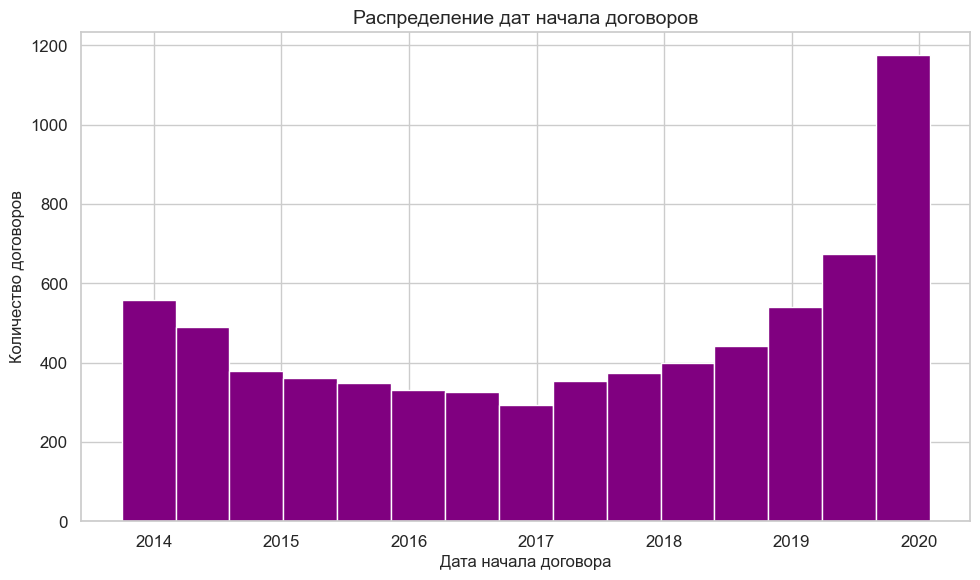

In [23]:
contract['begin_date'].hist(color='purple', bins=15)
plt.title('Распределение дат начала договоров', fontsize=14)
plt.xlabel('Дата начала договора', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

C середины анализируемого периода компании удалось сменить негативный тренд по количеству заключаемых ежемесячно договоров на позитивный и достичь значительного успеха к концу анализируемого периода.

#### end_date

In [24]:
contract['end_date'].unique()

array(['No', '2017-05-01', '2016-03-01', '2018-09-01', '2018-11-01',
       '2018-12-01', '2019-08-01', '2018-07-01', '2017-09-01',
       '2015-09-01', '2016-07-01', '2016-06-01', '2018-03-01',
       '2019-02-01', '2018-06-01', '2019-06-01', '2020-01-01',
       '2019-11-01', '2016-09-01', '2015-06-01', '2016-12-01',
       '2019-05-01', '2019-04-01', '2017-06-01', '2017-08-01',
       '2018-04-01', '2018-08-01', '2018-02-01', '2019-07-01',
       '2015-12-01', '2014-06-01', '2018-10-01', '2019-01-01',
       '2017-07-01', '2017-12-01', '2018-05-01', '2015-11-01',
       '2019-10-01', '2019-03-01', '2016-02-01', '2016-10-01',
       '2018-01-01', '2017-11-01', '2015-10-01', '2019-12-01',
       '2015-07-01', '2017-04-01', '2015-02-01', '2017-03-01',
       '2016-05-01', '2016-11-01', '2015-08-01', '2019-09-01',
       '2017-10-01', '2017-02-01', '2016-08-01', '2016-04-01',
       '2015-05-01', '2014-09-01', '2014-10-01', '2017-01-01',
       '2015-03-01', '2015-01-01', '2016-01-01', 

In [25]:
contract[contract['end_date'] == 'No']['end_date'].count()

5942

Значение 'No' заменим на пропуск, даты в виде текста приведем к корректному типу данных.

In [26]:
contract['end_date'] = contract['end_date'].replace('No', np.nan)

In [27]:
contract['end_date'] = pd.to_datetime(contract['end_date'])

In [28]:
contract['end_date'].describe()

count                             1101
mean     2018-03-12 18:21:15.204359680
min                2014-06-01 00:00:00
25%                2017-05-01 00:00:00
50%                2018-06-01 00:00:00
75%                2019-04-01 00:00:00
max                2020-01-01 00:00:00
Name: end_date, dtype: object

In [29]:
contract['end_date'].dt.year.sort_values().unique()

array([2014., 2015., 2016., 2017., 2018., 2019., 2020.,   nan])

In [30]:
contract['end_date'].dt.month.sort_values().unique()

array([ 1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., nan])

In [31]:
contract['end_date'].dt.day.sort_values().unique()

array([ 1., nan])

In [32]:
contract['end_date'].drop_duplicates().sort_values()

269    2014-06-01
1997   2014-09-01
2019   2014-10-01
6038   2014-11-01
5834   2014-12-01
          ...    
341    2019-10-01
148    2019-11-01
522    2019-12-01
137    2020-01-01
0             NaT
Name: end_date, Length: 67, dtype: datetime64[ns]

Первый закрытый договор - в июне 2014, начиная с сентября 2014 года договоры закрывались каждый месяц.

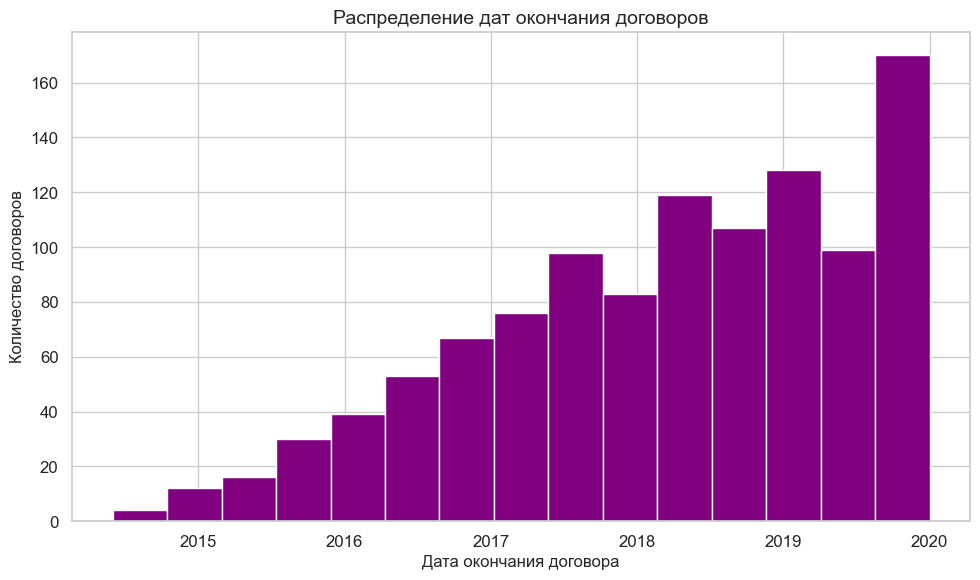

In [33]:
contract['end_date'].hist(color='purple', bins=15)
plt.title('Распределение дат окончания договоров', fontsize=14)
plt.xlabel('Дата окончания договора', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

В анализируемом периоде наблюдается тренд на увеличение количества расторгаемых ежемесячно договоров.

При этом нужно понимать, что абонентская база растет, возможно, относительный отток имеет не такую пугающую динамику.

В любом случае компании полезно и важно получить новый инструмент не только для привлечения новых абонентов, но и для удержания имеющихся, чем мы и занимаемся.

#### contract_closed - TARGET

Создадим таргет - бинарный признак, расторгнут ли договор.

In [34]:
contract['contract_closed'] = contract['end_date'].notna().astype(int)

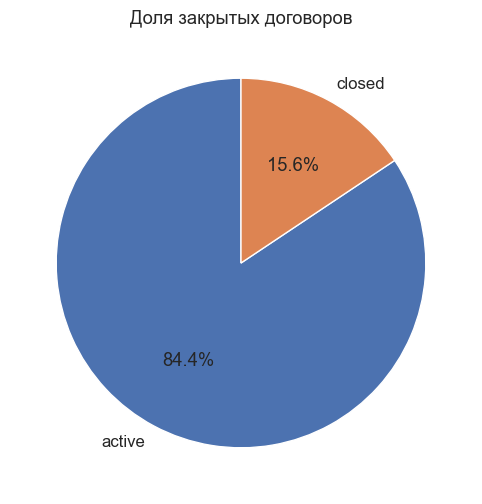

In [35]:
plt.pie(contract['contract_closed'].value_counts(), labels=['active', 'closed'], autopct='%1.1f%%', startangle=90)
plt.title('Доля закрытых договоров')
plt.show()

Данные не сбалансированы по таргету, это нужно учесть при формировании выборок.

#### type
Тип оплаты: раз в год-два или ежемесячно

In [36]:
contract['type'].unique()

array(['Month-to-month', 'One year', 'Two year'], dtype=object)

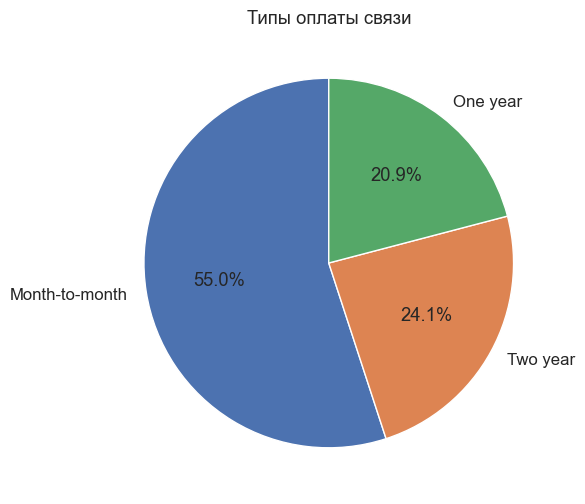

In [37]:
plt.pie(contract['type'].value_counts(), labels=contract['type'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Типы оплаты связи')
plt.show()

Большая часть абонентов оплачивает связь ежемесячно.

#### paperless_billing
Электронный расчётный лист.

In [38]:
contract['paperless_billing'].unique()

array(['Yes', 'No'], dtype=object)

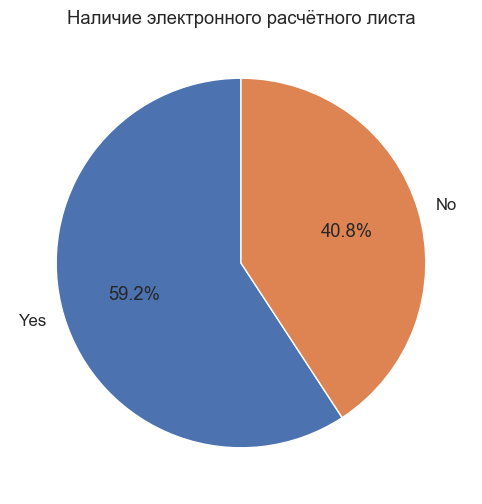

In [39]:
plt.pie(contract['paperless_billing'].value_counts(), labels=contract['paperless_billing'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Наличие электронного расчётного листа')
plt.show()

У большей части абонентов есть электронный расчётный лист.

#### payment_method
Тип платежа.

In [40]:
contract['payment_method'].unique()

array(['Electronic check', 'Mailed check', 'Bank transfer (automatic)',
       'Credit card (automatic)'], dtype=object)

- Electronic check — электронный платёж / оплата электронным чеком
- Mailed check — почтовый платёж / оплата почтовым чеком
- Bank transfer (automatic) — банковский перевод (автоматический)
- Credit card (automatic) — оплата кредитной картой (автоматический)

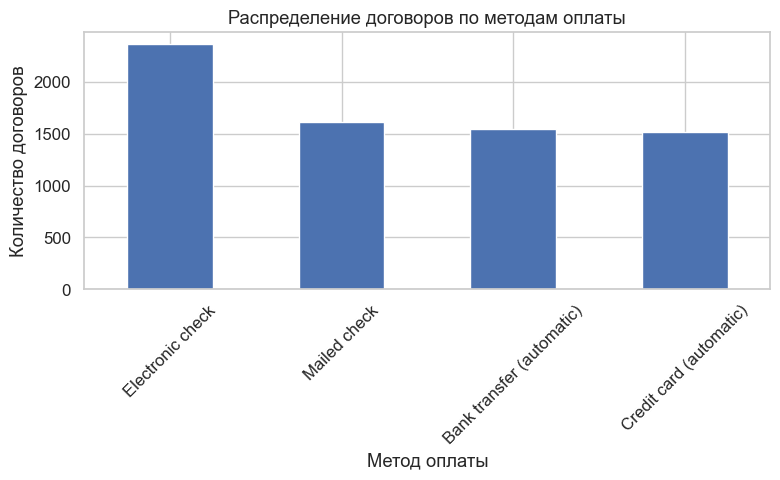

In [41]:
contract['payment_method'].value_counts().plot(kind='bar', figsize=(8, 5))
plt.title('Распределение договоров по методам оплаты')
plt.xlabel('Метод оплаты')
plt.ylabel('Количество договоров')
plt.xticks(rotation=45)      
plt.tight_layout()            
plt.show()

Доминирующая часть договоров оплачивается по электронному чеку. Другие способы оплаты встречаются примерно одинаково часто.

При этом надо понимать, что автоматические платежи банковским переводом и банковской картой - для клиента почти одно и то же.

#### monthly_charges
Приведем данные к корректному типу:

In [42]:
contract['monthly_charges'].unique()

array(['29.85', '56.95', '53.85', ..., '63.1', '44.2', '78.7'],
      dtype=object)

In [43]:
contract['monthly_charges'] = contract['monthly_charges'].str.replace(',', '.', regex=False).str.replace(' ', '', regex=False)

In [44]:
contract['monthly_charges'] = pd.to_numeric(contract['monthly_charges'])

In [45]:
contract['monthly_charges'].dtype, contract['monthly_charges'].isna().sum()

(dtype('float64'), 0)

Преобразование прошло успешно для всех строк.

In [46]:
contract['monthly_charges'].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: monthly_charges, dtype: float64

<AxesSubplot:>

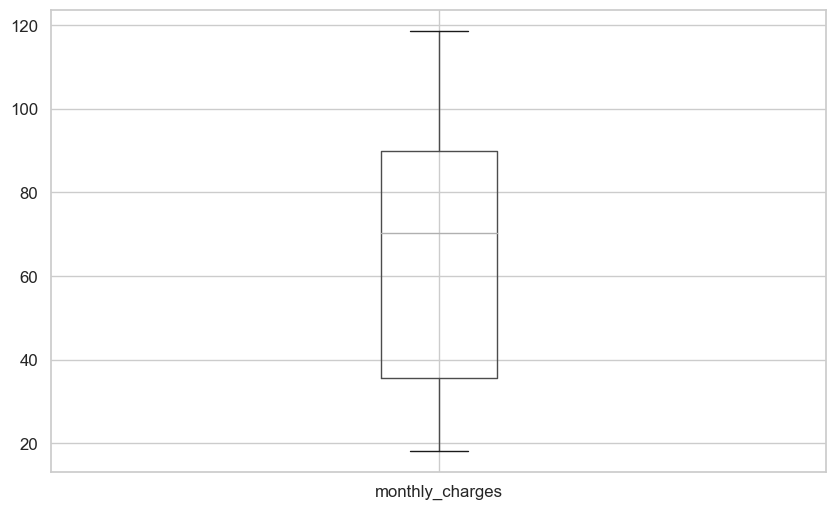

In [47]:
contract.boxplot('monthly_charges')

Аномалии не визуализируются.

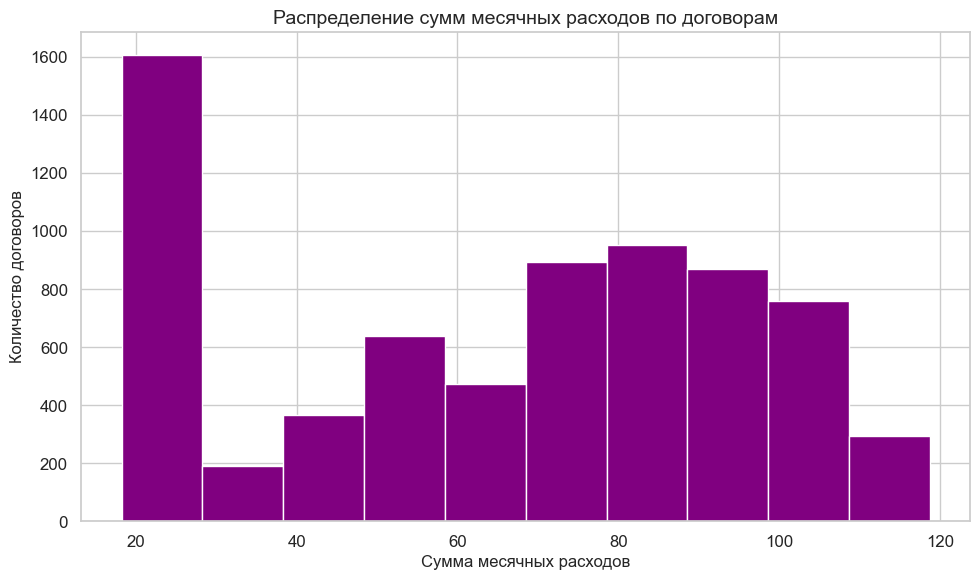

In [48]:
contract['monthly_charges'].hist(color='purple')
plt.title('Распределение сумм месячных расходов по договорам', fontsize=14)
plt.xlabel('Сумма месячных расходов', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

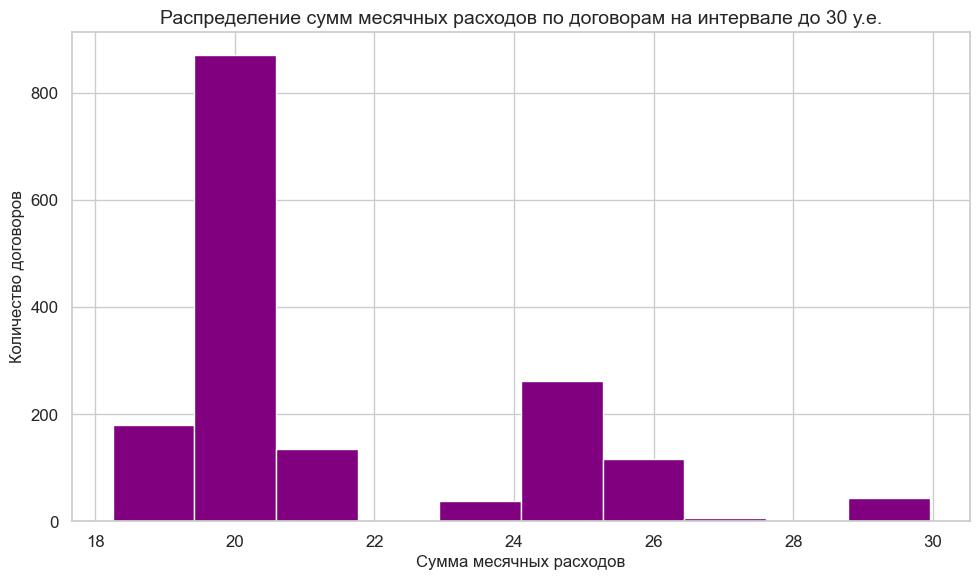

In [49]:
contract[contract['monthly_charges'] <= 30]['monthly_charges'].hist(color='purple')
plt.title('Распределение сумм месячных расходов по договорам на интервале до 30 у.е.', fontsize=14)
plt.xlabel('Сумма месячных расходов', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

В распределении месячных расходов видим два интервала:
- Один - большое количество низких значений с пиком в районе 20 у.е.
- Второй - большой интервал с пиком в районе 80-90 у.е.

Можем предположить, что в первый интервал попали договоры абонентов, которым подключена только телефонная связь. Остальные - пользователи интернета.

#### total_charges
Приведем данные к корректному типу:

In [50]:
contract['total_charges'].unique()

array(['31.04', '2071.84', '226.17', ..., '325.6', '520.8', '7251.82'],
      dtype=object)

In [51]:
contract['total_charges_raw'] = contract['total_charges']

In [52]:
contract['total_charges'] = contract['total_charges'].str.replace(',', '.', regex=False).str.replace(' ', '', regex=False)

In [53]:
contract['total_charges'] = pd.to_numeric(contract['total_charges'])

In [54]:
contract['total_charges'].dtype, contract['total_charges'].isna().sum()

(dtype('float64'), 11)

После преобразования получили 11 пропусков.

До обработки сохранен столбец в исходном виде - посмотрим, что было на месте пропусков.

Количество пропусков совпадает с количеством договоров с датой 01.02.2020, поэтому выведем столбец begin_date.

In [55]:
missing_mask = contract['total_charges'].isna()

contract.loc[missing_mask, ['customer_id', 'monthly_charges', 'total_charges_raw', 'begin_date']]

,customer_id,monthly_charges,total_charges_raw,begin_date
488,4472-LVYGI,52.55,,2020-02-01
753,3115-CZMZD,20.25,,2020-02-01
936,5709-LVOEQ,80.85,,2020-02-01
1082,4367-NUYAO,25.75,,2020-02-01
1340,1371-DWPAZ,56.05,,2020-02-01
3331,7644-OMVMY,19.85,,2020-02-01
3826,3213-VVOLG,25.35,,2020-02-01
4380,2520-SGTTA,20.00,,2020-02-01
5218,2923-ARZLG,19.70,,2020-02-01
6670,4075-WKNIU,73.35,,2020-02-01


In [56]:
contract.loc[missing_mask, 'total_charges_raw']

488      
753      
936      
1082     
1340     
3331     
3826     
4380     
5218     
6670     
6754     
Name: total_charges_raw, dtype: object

In [57]:
#Список id для удаления из других датафреймов
ids_to_drop = contract.loc[missing_mask, 'customer_id'].tolist()

В общих расходах по договорам с датой 01.02.2020 - пустая строка.

Подтверждено предположение, что это договоры, заключенные в день выгрузки данных. 

Удалим 11 строк.

In [58]:
contract = contract[contract['begin_date'] != pd.Timestamp('2020-02-01')]

In [59]:
contract = contract.drop('total_charges_raw', axis=1)

In [60]:
contract['total_charges'].describe()

count    7032.000000
mean     2118.621822
std      2112.736199
min        19.050000
25%       439.745000
50%      1345.275000
75%      3239.317500
max      9221.380000
Name: total_charges, dtype: float64

<AxesSubplot:>

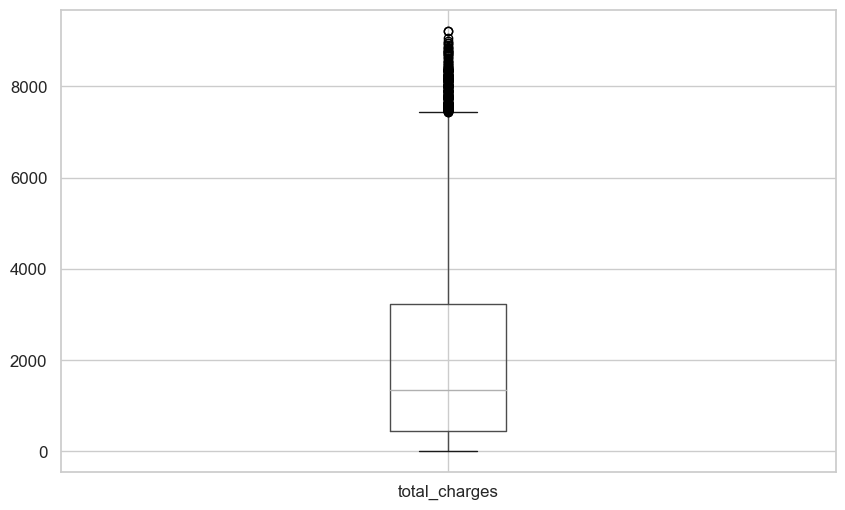

In [61]:
contract.boxplot('total_charges')

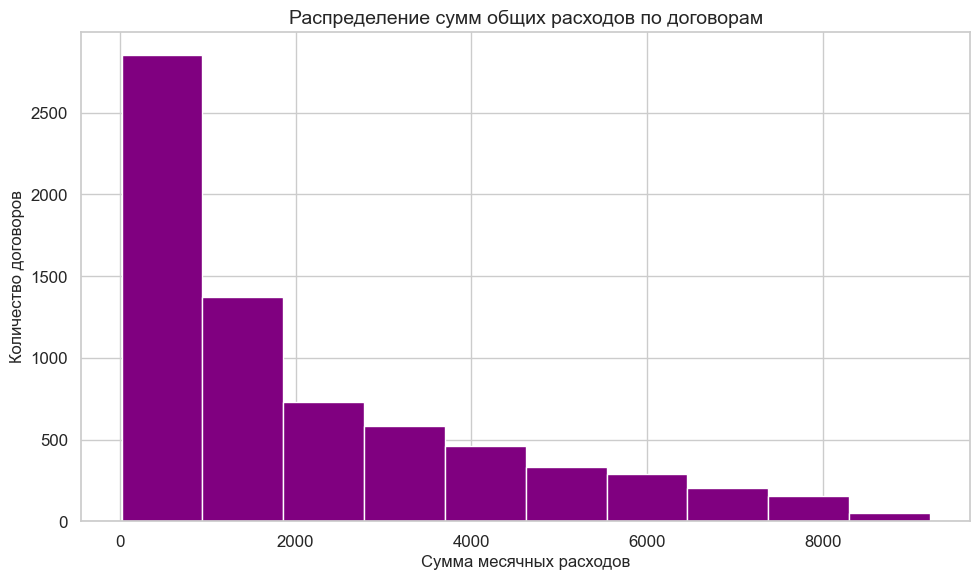

In [62]:
contract['total_charges'].hist(color='purple')
plt.title('Распределение сумм общих расходов по договорам', fontsize=14)
plt.xlabel('Сумма месячных расходов', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

На boxplot видим некоторое количество очень высоких значений. Они не являются аномалиями.

Распределение значений выглядит логично. Договоров с большими общими доходами (вероятно, очень длительных) меньше, чем остальных.

Покажем информацию о датафрейме после обработки:

In [63]:
contract.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   customer_id        7032 non-null   object        
 1   begin_date         7032 non-null   datetime64[ns]
 2   end_date           1101 non-null   datetime64[ns]
 3   type               7032 non-null   object        
 4   paperless_billing  7032 non-null   object        
 5   payment_method     7032 non-null   object        
 6   monthly_charges    7032 non-null   float64       
 7   total_charges      7032 non-null   float64       
 8   contract_closed    7032 non-null   int32         
dtypes: datetime64[ns](2), float64(2), int32(1), object(4)
memory usage: 521.9+ KB


Количество строк уменьшилось на 11. Типы данных корректны.

### personal
- customerID — ID пользователя;
- gender — пол;
- SeniorCitizen — является ли абонент пенсионером;
- Partner — есть ли у абонента супруг или супруга;
- Dependents — есть ли у абонента дети.

Сначала осмотрим информацию о таблице внутри базы данных. Затем выгрузим её, сразу приведем наименования столбцов к змеиному виду.

In [64]:
table_name = "personal" 
query = f"PRAGMA table_info({table_name})"
pd.read_sql_query(query, con=engine)

,cid,name,type,notnull,dflt_value,pk
0,0,customerID,TEXT,0,None,0
1,1,gender,TEXT,0,None,0
2,2,SeniorCitizen,TEXT,0,None,0
3,3,Partner,TEXT,0,None,0
4,4,Dependents,TEXT,0,None,0


In [65]:
personal = pd.read_sql_query("SELECT * FROM personal;", con=engine)

In [66]:
personal.columns = personal.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True).str.lower()

personal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     7043 non-null   object
 1   gender          7043 non-null   object
 2   senior_citizen  7043 non-null   object
 3   partner         7043 non-null   object
 4   dependents      7043 non-null   object
dtypes: object(5)
memory usage: 275.2+ KB


In [67]:
contract.duplicated().sum()

0

Пропуски и дубликаты отсутствуют.

#### customer_id

In [68]:
personal['customer_id'].nunique()

7043

In [69]:
(contract['customer_id'].isin(personal['customer_id'].tolist())).sum()

7032

В personal те же 7043 уникальных id абонента, что и в contract.
Удалим 11 абонентов, заключивших договоры в день выгрузки.

In [70]:
personal = personal[~personal['customer_id'].isin(ids_to_drop)]
personal['customer_id'].nunique()

7032

#### gender

In [71]:
personal['gender'].unique()

array(['Female', 'Male'], dtype=object)

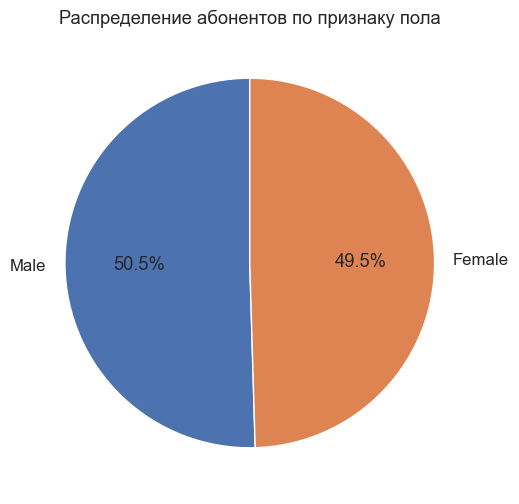

In [72]:
plt.pie(personal['gender'].value_counts(), labels=personal['gender'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по признаку пола')
plt.show()

Среди абонентов женщин и мужчин примерно поровну.

#### senior_citizen
Является ли абонент пенсионером.

In [73]:
personal['senior_citizen'].unique()

array(['0', '1'], dtype=object)

In [74]:
personal['senior_citizen'] = personal['senior_citizen'].map({'1': 'Yes', '0': 'No'})
personal['senior_citizen'].unique()

array(['No', 'Yes'], dtype=object)

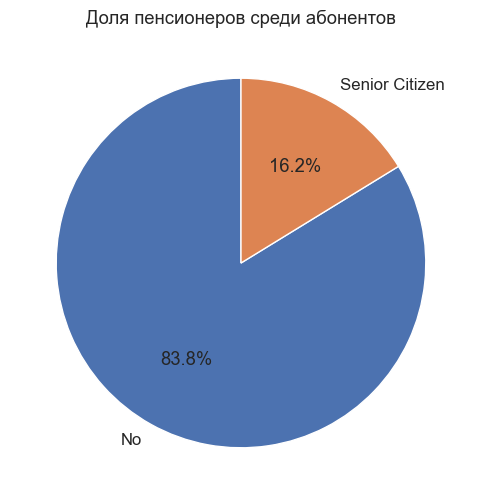

In [75]:
plt.pie(personal['senior_citizen'].value_counts(), labels=['No', 'Senior Citizen'], autopct='%1.1f%%', startangle=90)
plt.title('Доля пенсионеров среди абонентов')
plt.show()

Доля пенсионеров невелика.

#### partner
Есть ли у абонента супруг или супруга.

In [76]:
personal['partner'].unique()

array(['Yes', 'No'], dtype=object)

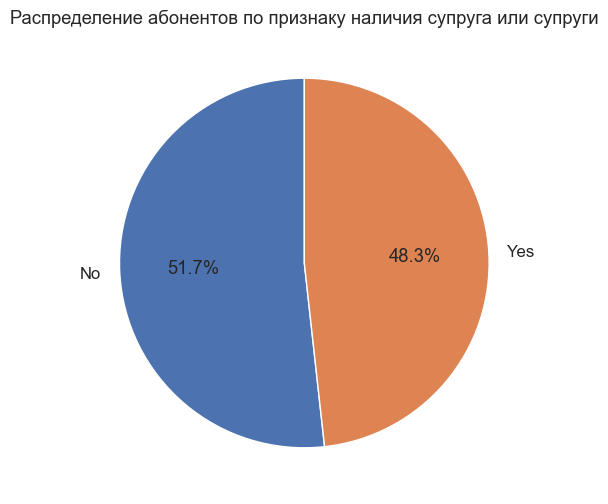

In [77]:
plt.pie(personal['partner'].value_counts(), labels=personal['partner'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по признаку наличия супруга или супруги')
plt.show()

Супруга или супругу имеет чуть больше половины абонентов.

#### dependents
Есть ли у абонента дети.

In [78]:
personal['dependents'].unique()

array(['No', 'Yes'], dtype=object)

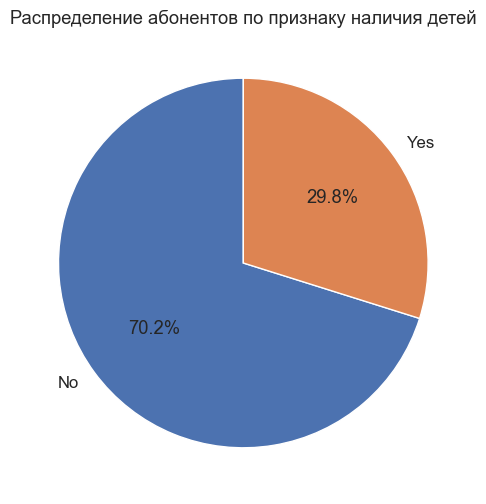

In [79]:
plt.pie(personal['dependents'].value_counts(), labels=personal['dependents'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по признаку наличия детей')
plt.show()

Дети есть менее, чем у трети абонентов.

### internet
- customerID — ID пользователя;
- InternetService — тип подключения;
- OnlineSecurity — блокировка опасных сайтов;
- OnlineBackup — облачное хранилище файлов для резервного копирования данных;
- DeviceProtection — антивирус;
- TechSupport — выделенная линия технической поддержки;
- StreamingTV — стриминговое телевидение;
- StreamingMovies — каталог фильмов.

Сначала осмотрим информацию о таблице внутри базы данных. Затем выгрузим её, сразу приведем наименования столбцов к змеиному виду.

In [80]:
table_name = "internet" 
query = f"PRAGMA table_info({table_name})"
pd.read_sql_query(query, con=engine)

,cid,name,type,notnull,dflt_value,pk
0,0,customerID,TEXT,0,None,0
1,1,InternetService,TEXT,0,None,0
2,2,OnlineSecurity,TEXT,0,None,0
3,3,OnlineBackup,TEXT,0,None,0
4,4,DeviceProtection,TEXT,0,None,0
5,5,TechSupport,TEXT,0,None,0
6,6,StreamingTV,TEXT,0,None,0
7,7,StreamingMovies,TEXT,0,None,0


In [81]:
internet = pd.read_sql_query("SELECT * FROM internet;", con=engine)

In [82]:
internet.columns = internet.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True).str.lower()

internet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   customer_id        5517 non-null   object
 1   internet_service   5517 non-null   object
 2   online_security    5517 non-null   object
 3   online_backup      5517 non-null   object
 4   device_protection  5517 non-null   object
 5   tech_support       5517 non-null   object
 6   streaming_tv       5517 non-null   object
 7   streaming_movies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


In [83]:
internet.duplicated().sum()

0

Пропуски и дубликаты отсутствуют.

#### customer_id

In [84]:
internet['customer_id'].nunique()

5517

Удалим пользователей интернета, заключивших договоры в день выгрузки, если они есть.

In [85]:
internet = internet[~internet['customer_id'].isin(ids_to_drop)]
internet['customer_id'].nunique()

5512

In [86]:
(internet['customer_id'].isin(personal['customer_id'].tolist())).sum()

5512

Все 5512 пользователей интернета есть в таблицах personal и, соответственно, contract.

#### internet_service
Тип подключения

In [87]:
internet['internet_service'].unique()

array(['DSL', 'Fiber optic'], dtype=object)

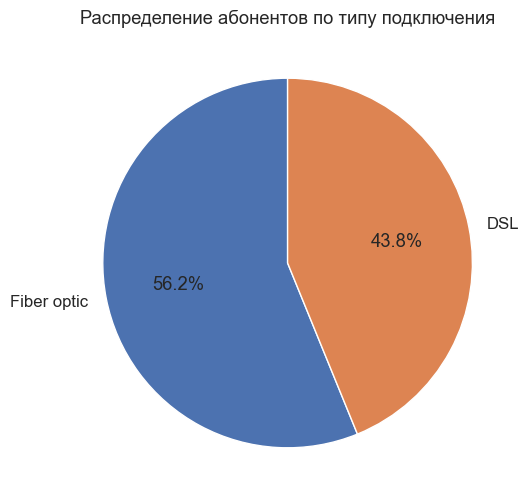

In [88]:
plt.pie(internet['internet_service'].value_counts(), labels=internet['internet_service'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по типу подключения')
plt.show()

Подключение по оптоволокну преобладает.

#### интернет-услуги

In [89]:
internet_services = ['online_security', 'online_backup', 'device_protection', 
                    'tech_support', 'streaming_tv', 'streaming_movies']

for column in internet_services:
    display(f"{column}: {internet[column].unique()}")

"online_security: ['No' 'Yes']"

"online_backup: ['Yes' 'No']"

"device_protection: ['No' 'Yes']"

"tech_support: ['No' 'Yes']"

"streaming_tv: ['No' 'Yes']"

"streaming_movies: ['No' 'Yes']"

6 столбцов с интернет-услугами заболнены бинарно: есть/нет. Построим круговые диаграммы распределений.

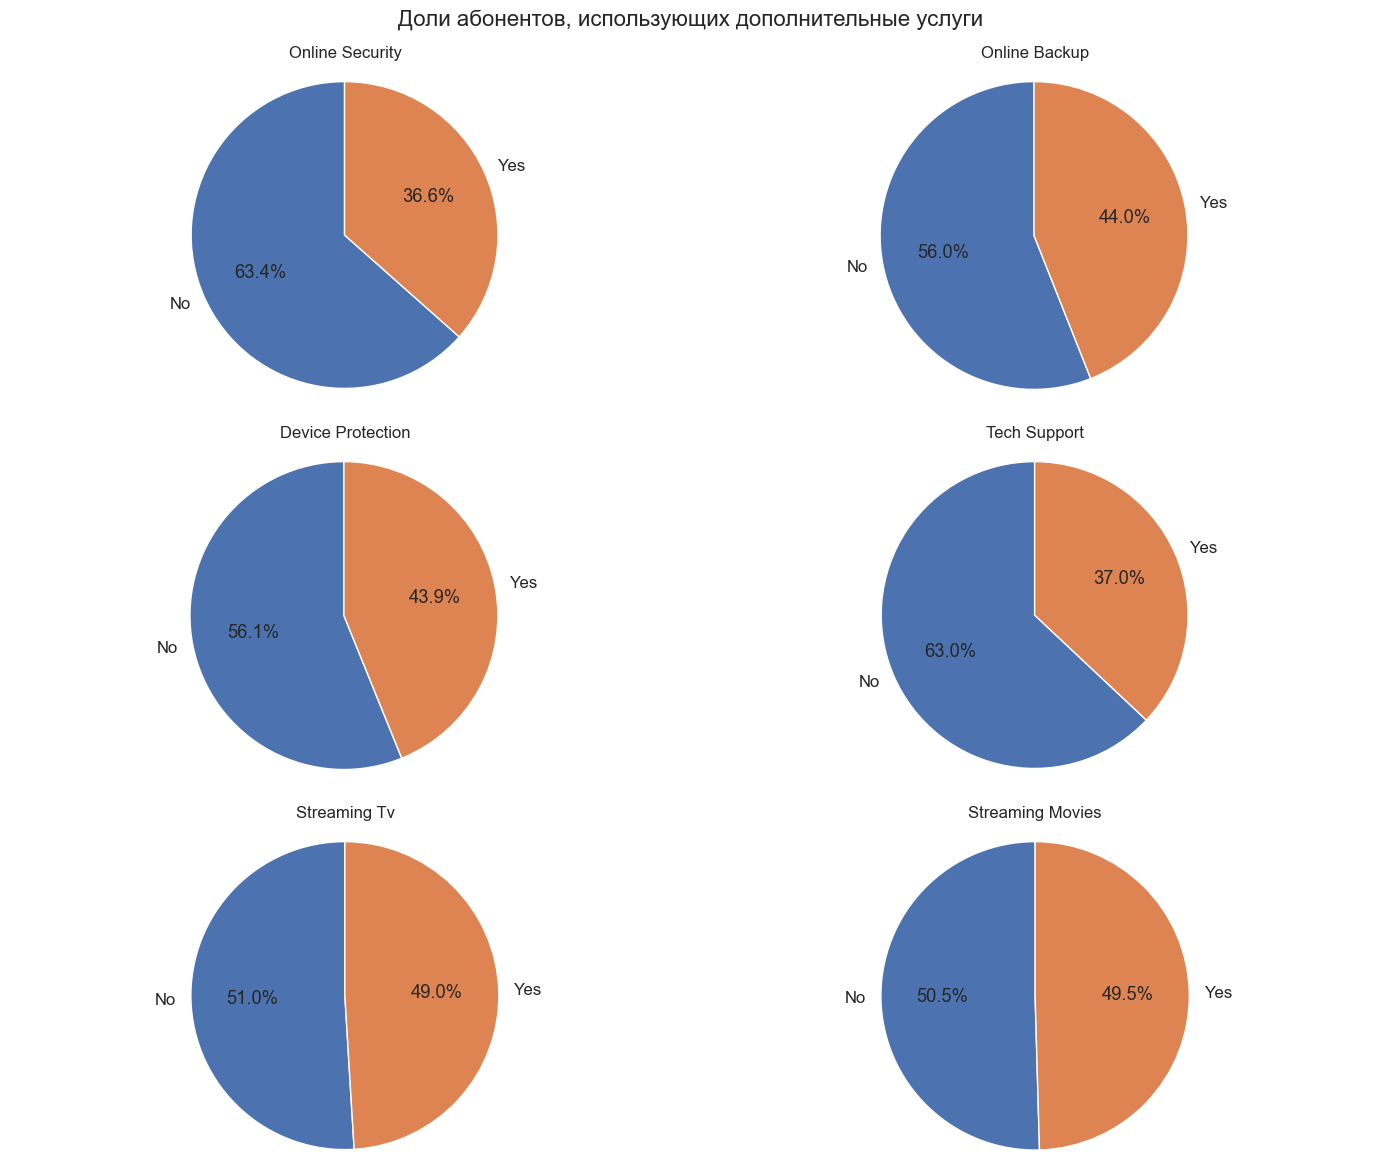

In [90]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()

for i, col in enumerate(internet_services):
    ax = axes[i]
    counts = internet[col].value_counts()
    
    ax.pie(internet[col].value_counts(), labels=internet[col].value_counts().index, autopct='%1.1f%%', startangle=90)
    ax.set_title(col.replace('_', ' ').title(), fontsize=12)
    ax.axis('equal')

plt.suptitle('Доли абонентов, использующих дополнительные услуги', fontsize=16)
plt.tight_layout()
plt.show()

По каждой из услуг доля использующих её абонентов меньше 50%.

### phone
- customerID — ID пользователя;
- MultipleLines — подключение телефона к нескольким линиям одновременно.

Сначала осмотрим информацию о таблице внутри базы данных. Затем выгрузим её, сразу приведем наименования столбцов к змеиному виду.

In [91]:
table_name = "phone" 
query = f"PRAGMA table_info({table_name})"
pd.read_sql_query(query, con=engine)

,cid,name,type,notnull,dflt_value,pk
0,0,CustomerId,TEXT,0,None,0
1,1,MultipleLines,TEXT,0,None,0


In [92]:
phone = pd.read_sql_query("SELECT * FROM phone;", con=engine)

In [93]:
phone.columns = phone.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True).str.lower()

phone.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customer_id     6361 non-null   object
 1   multiple_lines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


In [94]:
phone.duplicated().sum()

0

Пропуски и дубликаты отсутствуют.

#### customer_id

In [95]:
phone['customer_id'].nunique()

6361

Удалим пользователей телефона, заключивших договоры в день выгрузки, если они есть.

In [96]:
phone = phone[~phone['customer_id'].isin(ids_to_drop)]
phone['customer_id'].nunique()

6352

In [97]:
(phone['customer_id'].isin(personal['customer_id'].tolist())).sum()

6352

Все 6352 пользователя интернета есть в таблицах personal и, соответственно, contract.

#### multiple_lines
Подключение телефона к нескольким линиям одновременно.

In [98]:
phone['multiple_lines'].unique()

array(['No', 'Yes'], dtype=object)

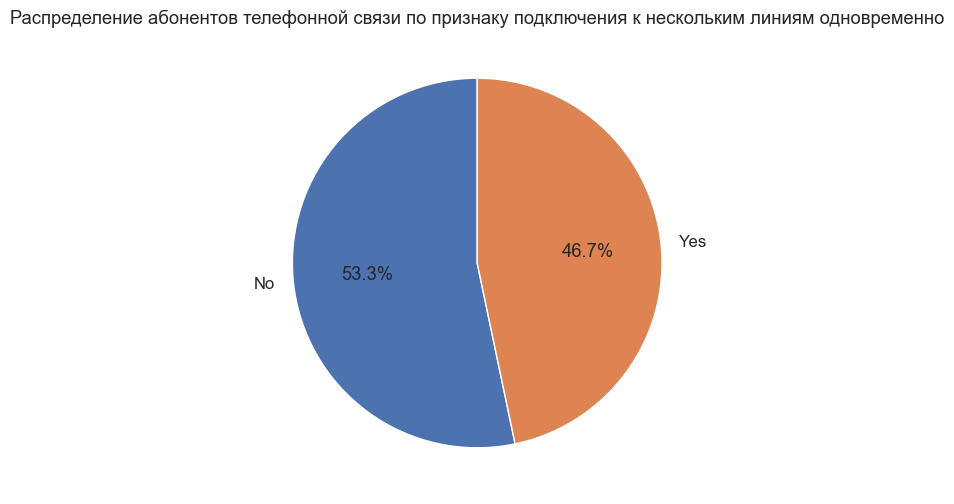

In [99]:
plt.pie(phone['multiple_lines'].value_counts(), labels=phone['multiple_lines'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов телефонной связи по признаку подключения к нескольким линиям одновременно')
plt.show()

Почти половина телефонов подключены к нескольким линиям одновременно.

### Объединение таблиц

Объединим таблицы по customer_id и выведем информацию о получившемся датафрейме.

In [100]:
data_all = (personal.merge(contract, on='customer_id', how='left')
                    .merge(internet, on='customer_id', how='left')
                    .merge(phone, on='customer_id', how='left')).drop('customer_id', axis=1)


In [101]:
data_all = data_all[['contract_closed'] + [c for c in data_all.columns if c != 'contract_closed']]

display(data_all.info())
data_all.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   contract_closed    7032 non-null   int32         
 1   gender             7032 non-null   object        
 2   senior_citizen     7032 non-null   object        
 3   partner            7032 non-null   object        
 4   dependents         7032 non-null   object        
 5   begin_date         7032 non-null   datetime64[ns]
 6   end_date           1101 non-null   datetime64[ns]
 7   type               7032 non-null   object        
 8   paperless_billing  7032 non-null   object        
 9   payment_method     7032 non-null   object        
 10  monthly_charges    7032 non-null   float64       
 11  total_charges      7032 non-null   float64       
 12  internet_service   5512 non-null   object        
 13  online_security    5512 non-null   object        
 14  online_b

None

,contract_closed,gender,senior_citizen,partner,dependents,begin_date,end_date,type,paperless_billing,payment_method,monthly_charges,total_charges,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,multiple_lines
0,0,Female,No,Yes,No,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,31.04,DSL,No,Yes,No,No,No,No,NaN
1,0,Male,No,No,No,2017-04-01,NaT,One year,No,Mailed check,56.95,2071.84,DSL,Yes,No,Yes,No,No,No,No
2,0,Male,No,No,No,2019-10-01,NaT,Month-to-month,Yes,Mailed check,53.85,226.17,DSL,Yes,Yes,No,No,No,No,No


Объединение прошло корректно.

Проверим значения в столбцах кроме непрерывных числовых:

In [102]:
cols_to_check_unique = [
    col for col in data_all.columns
    if data_all[col].dtype not in ['datetime64[ns]', 'float64']
]

unique_dict = {col: data_all[col].unique().tolist() for col in cols_to_check_unique}

for col, vals in unique_dict.items():
    display(f"{col}: {vals}")

'contract_closed: [0, 1]'

"gender: ['Female', 'Male']"

"senior_citizen: ['No', 'Yes']"

"partner: ['Yes', 'No']"

"dependents: ['No', 'Yes']"

...

"device_protection: ['No', 'Yes', nan]"

"tech_support: ['No', 'Yes', nan]"

"streaming_tv: ['No', 'Yes', nan]"

"streaming_movies: ['No', 'Yes', nan]"

"multiple_lines: [nan, 'No', 'Yes']"

Пропуски необходимо будет заполнить. Сделаем это позднее. Для начала создадим несколько дополнительных признаков.

### Новые признаки
#### has_internet и has_phone
Отстутствие телефона и интернета видно в датафрейме по пропускам в multiple_lines и payment_method (а также других интернет-услугах).

Обозначим явно наличие телефона и интернета бинарными признаками 0/1. 

In [103]:
data_all['has_internet'] = data_all['internet_service'].notna().astype(int)
data_all['has_phone'] = data_all['multiple_lines'].notna().astype(int)

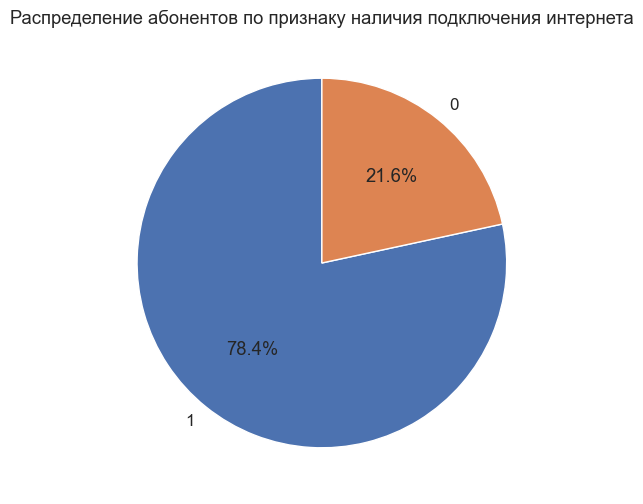

In [104]:
plt.pie(data_all['has_internet'].value_counts(), labels=data_all['has_internet'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по признаку наличия подключения интернета')
plt.show()

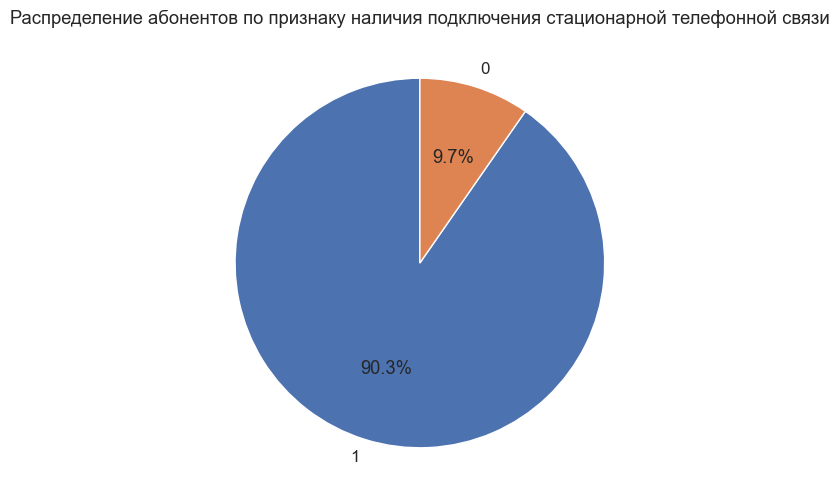

In [105]:
plt.pie(data_all['has_phone'].value_counts(), labels=data_all['has_phone'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по признаку наличия подключения стационарной телефонной связи')
plt.show()

Телефон есть у 90% абонентов, интернет только у 78%.

#### contract_duration_years
Рассчитаем длительность договоров в годах: до закрытия или до 01.02.2020.

Сразу удалим столбцы begin_date и end_date. Они больше не нужны.

In [106]:
data_all['contract_duration_years'] = round(((data_all['end_date'].fillna(pd.to_datetime('2020-02-01')) - data_all['begin_date']).dt.days / 365), 2)
data_all = data_all.drop(['begin_date', 'end_date'], axis=1)

In [107]:
data_all['contract_duration_years'].describe()

count    7032.000000
mean        2.465044
std         1.870443
min         0.080000
25%         0.760000
50%         2.080000
75%         4.000000
max         6.340000
Name: contract_duration_years, dtype: float64

<AxesSubplot:>

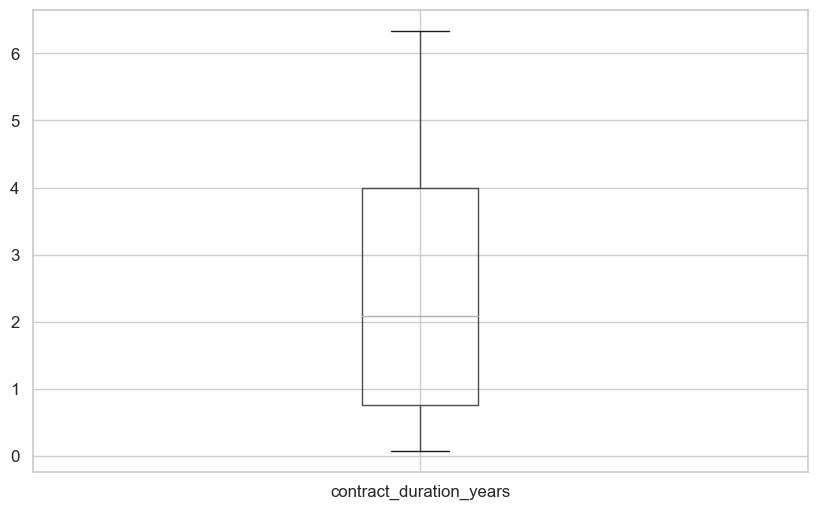

In [108]:
data_all.boxplot('contract_duration_years')

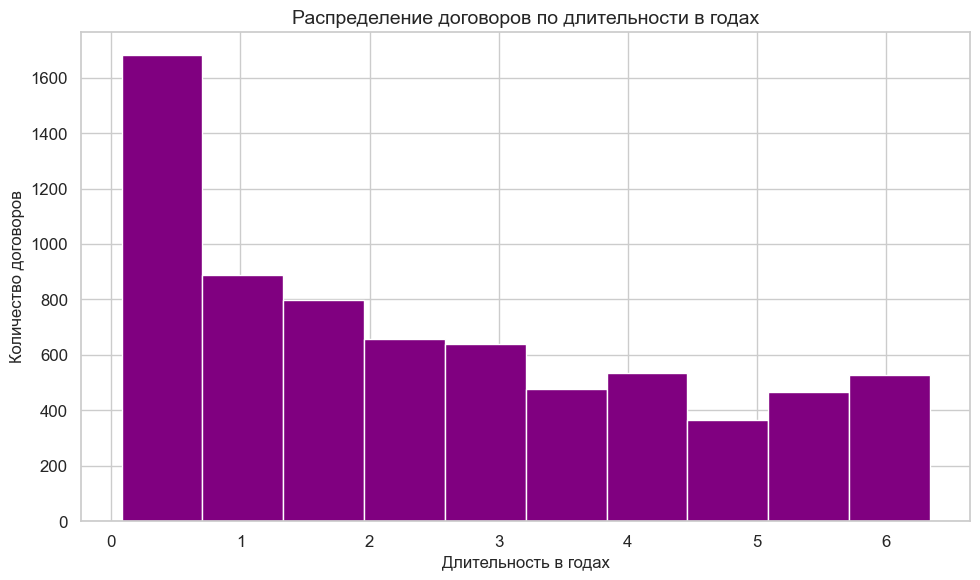

In [109]:
data_all['contract_duration_years'].hist(color='purple')
plt.title('Распределение договоров по длительности в годах', fontsize=14)
plt.xlabel('Длительность в годах', fontsize=12)
plt.ylabel('Количество договоров', fontsize=12)
plt.tight_layout()
plt.show()

Распределение ожидаемо. Чем больше срок договора, тем меньше договоров до него "доживают".

#### contract_is_new
Создадим бинарный признак "новый договор". Новым будем считать договор длительностью до полугода.

In [110]:
data_all['contract_is_new'] = (data_all['contract_duration_years'] <= 0.5).astype(int)

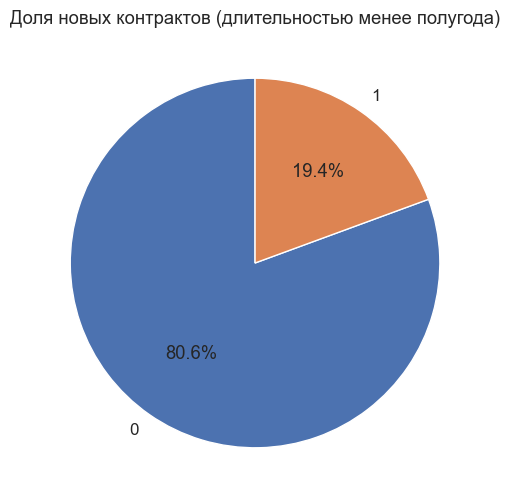

In [111]:
plt.pie(data_all['contract_is_new'].value_counts(), labels=data_all['contract_is_new'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Доля новых контрактов (длительностью менее полугода)')
plt.show()

19% договоров действуют не более полугода.

#### paid_month_count

Признак paid_month_count можно было бы кодировать OrdinalEncoder.

Вместо этого, чтобы явно показать не просто порядок, а количственную соотносимость значений, переведем признак в числовой - числом обозначим количество оплачиваемых за раз месяцев.

In [112]:
paid_month_map = {'Month-to-month': 1, 'One year': 12, 'Two year': 24}

data_all['paid_month_count'] = data_all['type'].map(paid_month_map)

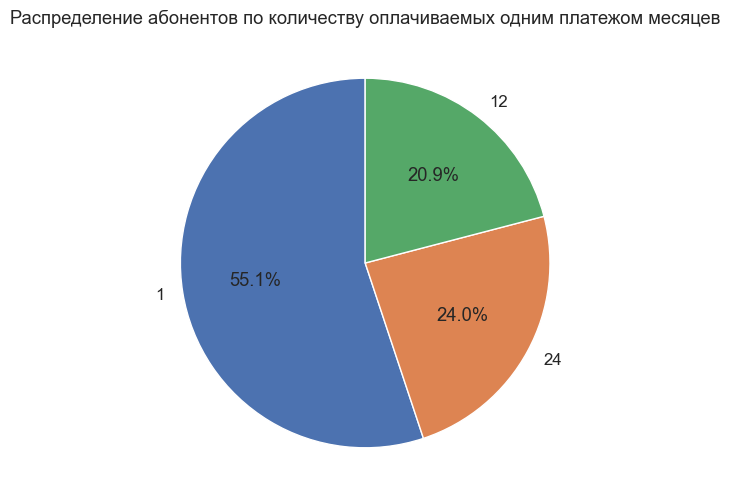

In [113]:
plt.pie(data_all['paid_month_count'].value_counts(), labels=data_all['paid_month_count'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по количеству оплачиваемых одним платежом месяцев')
plt.show()

#### autopay

При анализе признака payment_method мы заметили, что 2 из его значений по сути означают одно и тоже - автоматическое списание средств со счета или карты абонента. Другие 2 значения - оплата по счету электронному или почтовому.

Введем бинарный признак - наличие автоплатежа.

In [114]:
data_all['autopay'] = data_all['payment_method'].str.contains('automatic').astype(int)

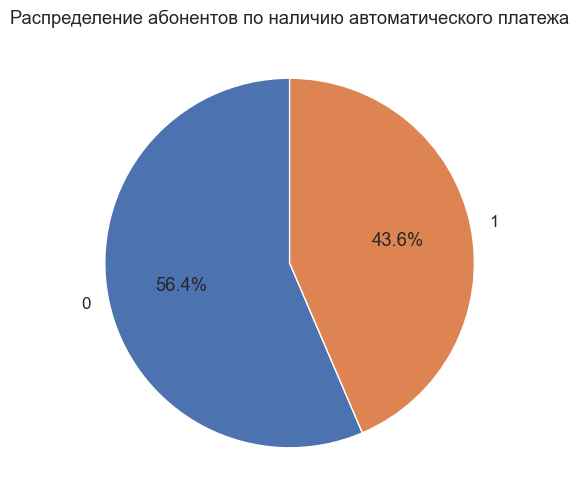

In [115]:
plt.pie(data_all['autopay'].value_counts(), labels=data_all['autopay'].value_counts().index, autopct='%1.1f%%', startangle=90)
plt.title('Распределение абонентов по наличию автоматического платежа')
plt.show()

Автоплатеж подключен менее, чем у половины абонентов.

#### internet_services_count
Посчитаем для каждого абонента количество подключенных интернет-услуг.

In [116]:
data_all['internet_services_count'] = (data_all[internet_services] == 'Yes').sum(axis=1)
data_all['internet_services_count'] = np.where((data_all['has_internet'] == 1), data_all['internet_services_count'], np.nan)

In [117]:
data_all['internet_services_count'].unique()

array([ 1.,  2.,  3.,  0.,  4., nan,  5.,  6.])

У абонентов без интернета пропуск для наглядности визуализации:

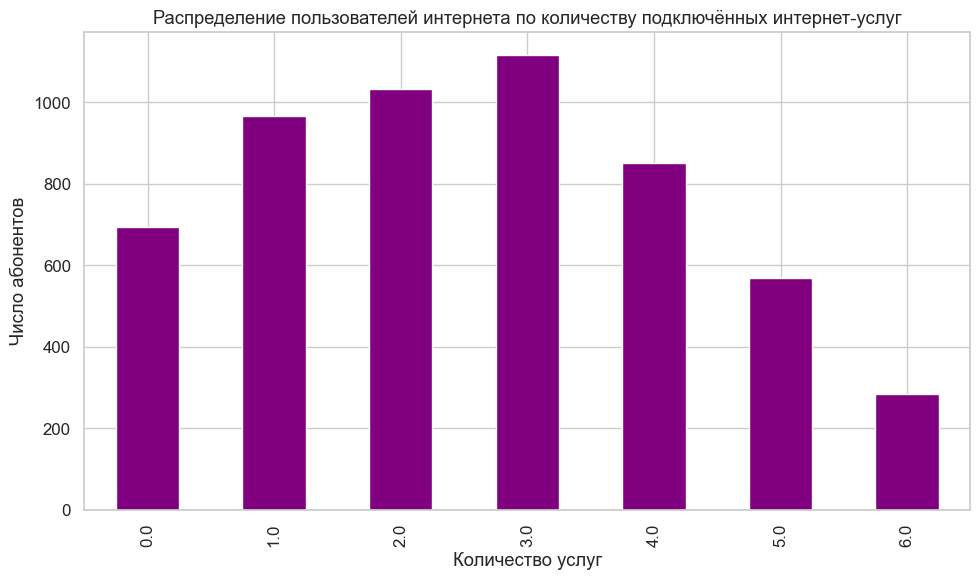

In [118]:
data_all.groupby('internet_services_count').size().plot(kind='bar', color='purple')
plt.title('Распределение пользователей интернета по количеству подключённых интернет-услуг')
plt.xlabel('Количество услуг')
plt.ylabel('Число абонентов')
plt.tight_layout()
plt.show()

Вид распределения количества подключенных дополнительных интернет-услуг напоминает колокол.

Признак числовой, вернем обратно на место пропусков нули.

In [119]:
data_all['internet_services_count'] = (data_all[internet_services] == 'Yes').sum(axis=1)

In [120]:
data_all['internet_services_count'].unique()

array([1, 2, 3, 0, 4, 5, 6], dtype=int64)

### Пропуски

Пропуски в датафрейме связаны с отсутствием у абонента телефона или интернета. Поэтому в соответствующих категориальных столбцах с дополнительными услугами укажем "неприменимо".

In [121]:
cat_cols_with_nan = [
    'internet_service',
    'online_security', 'online_backup', 'device_protection',
    'tech_support', 'streaming_tv', 'streaming_movies',
    'multiple_lines'
]

data_all[cat_cols_with_nan] = data_all[cat_cols_with_nan].fillna('N/A')

In [122]:
data_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 25 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   contract_closed          7032 non-null   int32  
 1   gender                   7032 non-null   object 
 2   senior_citizen           7032 non-null   object 
 3   partner                  7032 non-null   object 
 4   dependents               7032 non-null   object 
 5   type                     7032 non-null   object 
 6   paperless_billing        7032 non-null   object 
 7   payment_method           7032 non-null   object 
 8   monthly_charges          7032 non-null   float64
 9   total_charges            7032 non-null   float64
 10  internet_service         7032 non-null   object 
 11  online_security          7032 non-null   object 
 12  online_backup            7032 non-null   object 
 13  device_protection        7032 non-null   object 
 14  tech_support            

Проверим значения:

In [123]:
cols_to_check_unique = [
    col for col in data_all.columns
    if data_all[col].dtype not in ['datetime64[ns]', 'float64']
]

unique_dict = {col: data_all[col].unique().tolist() for col in cols_to_check_unique}

for col, vals in unique_dict.items():
    display(f"{col}: {vals}")

'contract_closed: [0, 1]'

"gender: ['Female', 'Male']"

"senior_citizen: ['No', 'Yes']"

"partner: ['Yes', 'No']"

"dependents: ['No', 'Yes']"

...

'has_phone: [0, 1]'

'contract_is_new: [1, 0]'

'paid_month_count: [1, 12, 24]'

'autopay: [0, 1]'

'internet_services_count: [1, 2, 3, 0, 4, 5, 6]'

### Визуализация соотношения ушедших и оставшихся абонентов для признаков
#### бинарные и категориальные признаки

In [124]:
cat_cols_vis = [
    'gender', 'senior_citizen', 'partner', 'dependents',
    'type', 'paperless_billing', 'autopay', 'internet_service',
    'online_security', 'online_backup', 'device_protection',
    'tech_support', 'streaming_tv', 'streaming_movies',
    'multiple_lines',
    'has_internet', 'has_phone', 'contract_is_new'
]

n_cols = 3
n_rows = 6

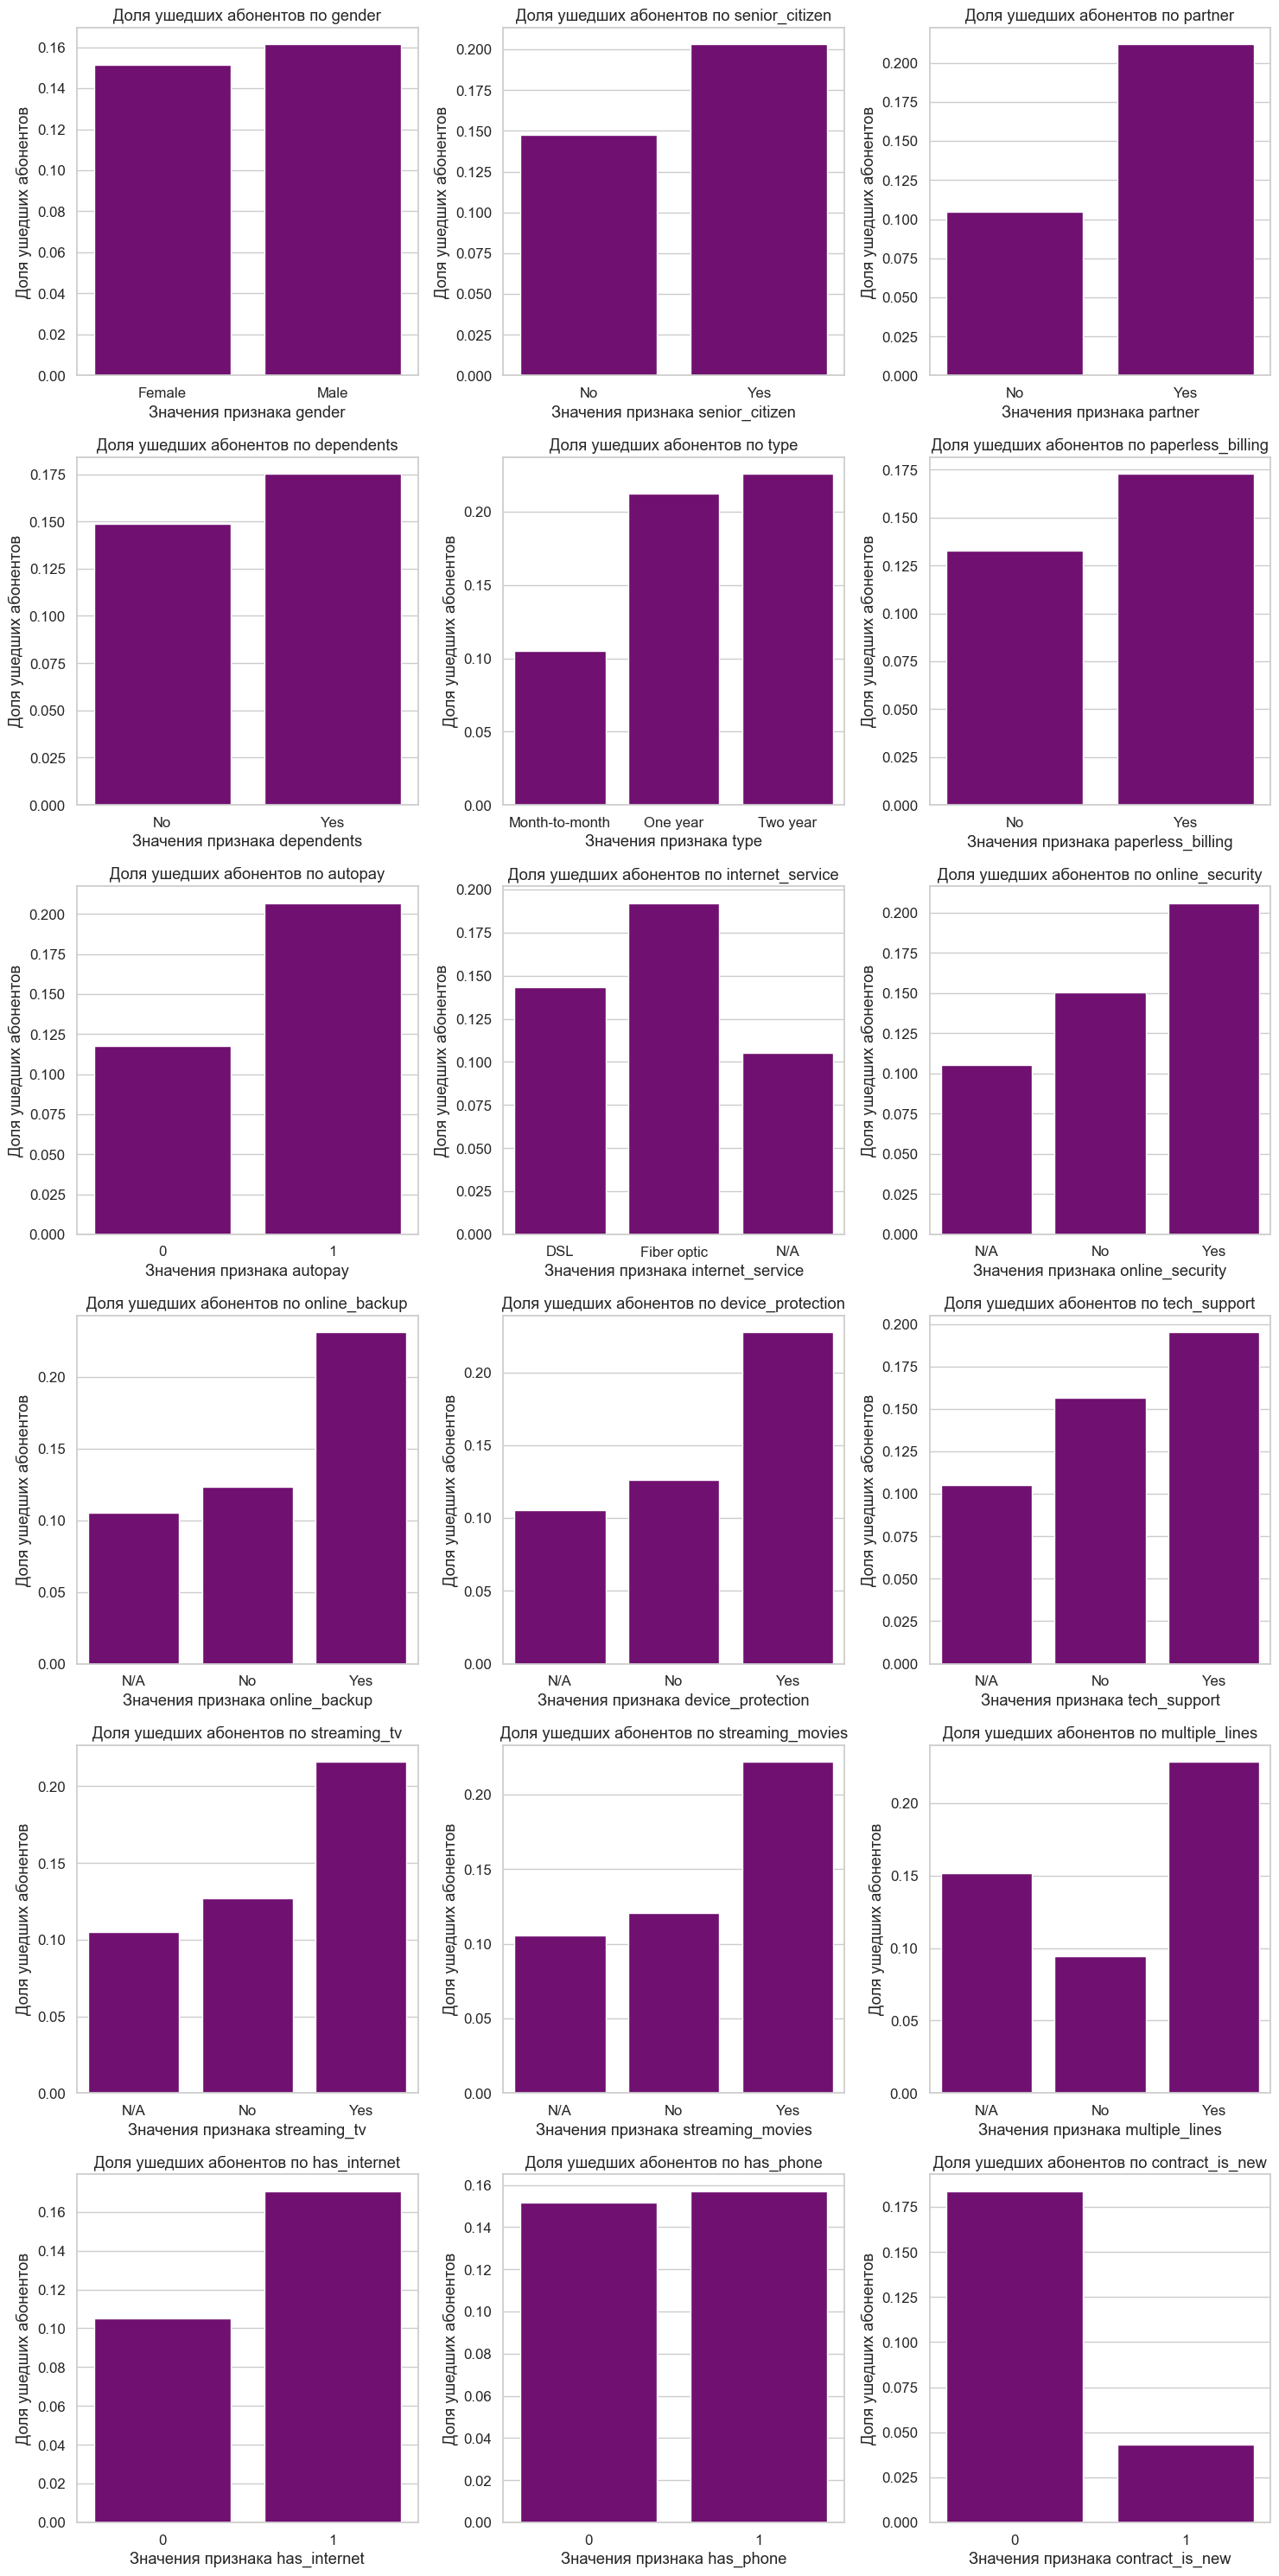

In [125]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5*n_rows))
axes = axes.flatten()

for i, col in enumerate(cat_cols_vis):
    df_plot = data_all[[col]].copy()
    df_plot['contract_closed'] = data_all['contract_closed']
    
    agg = df_plot.groupby(col)['contract_closed'].mean().reset_index()
    agg.columns = [col, 'share_closed']
    
    ax = axes[i]
    sns.barplot(data=agg, x=col, y='share_closed', ax=ax, color='purple')
    ax.set_title(f'Доля ушедших абонентов по {col}')
    ax.set_xlabel(f'Значения признака {col}')
    ax.set_ylabel('Доля ушедших абонентов')
    ax.tick_params(axis='x')

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

На графиках видно, при каких значениях признаков абоненты уходят чаще, при каких реже.

Результаты в большинстве своем неожиданны. Оказывается, подключение автоплатежа, дополнительных интернет-услуг ассоциируется с большей вероятностью расторжения договора. Доля расторгнутых договров сроком до 6 месяцев небольшая в сравнении с договорами других сроков.

#### числовые признаки

In [126]:
num_cols_vis = ['monthly_charges', 'total_charges', 'contract_duration_years']

n_cols = 1
n_rows = 3

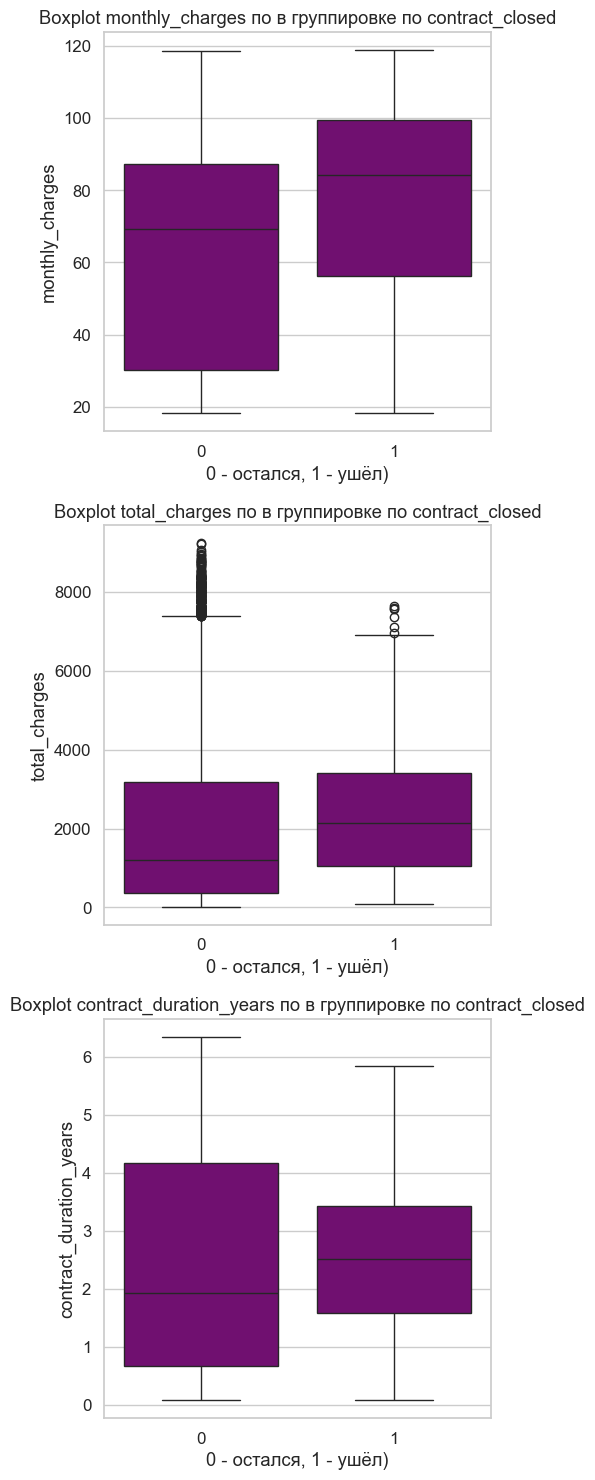

In [127]:
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5, 5*n_rows))
axes = axes.flatten()

df_num = data_all[num_cols_vis].copy()
df_num['contract_closed'] = data_all['contract_closed'].astype('category')

for i, col in enumerate(num_cols_vis):
    ax = axes[i]
    sns.boxplot(data=df_num, x='contract_closed', y=col, ax=ax, color='purple')
    ax.set_title(f'Boxplot {col} по в группировке по contract_closed')
    ax.set_xlabel('0 - остался, 1 - ушёл)')

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Уходили абоненты чаще с более высокими расходами на связь. Вероятно, это связано с тем, что пользователи только телефона меняют оператора редко.

Договоры чаще расторгаются на средних сроках - от 2 до 3 лет.

### Корреляционный анализ

Так как в данных признаки разных типов, применим для анализа phik_matrix.

paid_month_count укажем как числовой признак. Его исходная форма - категориальный.

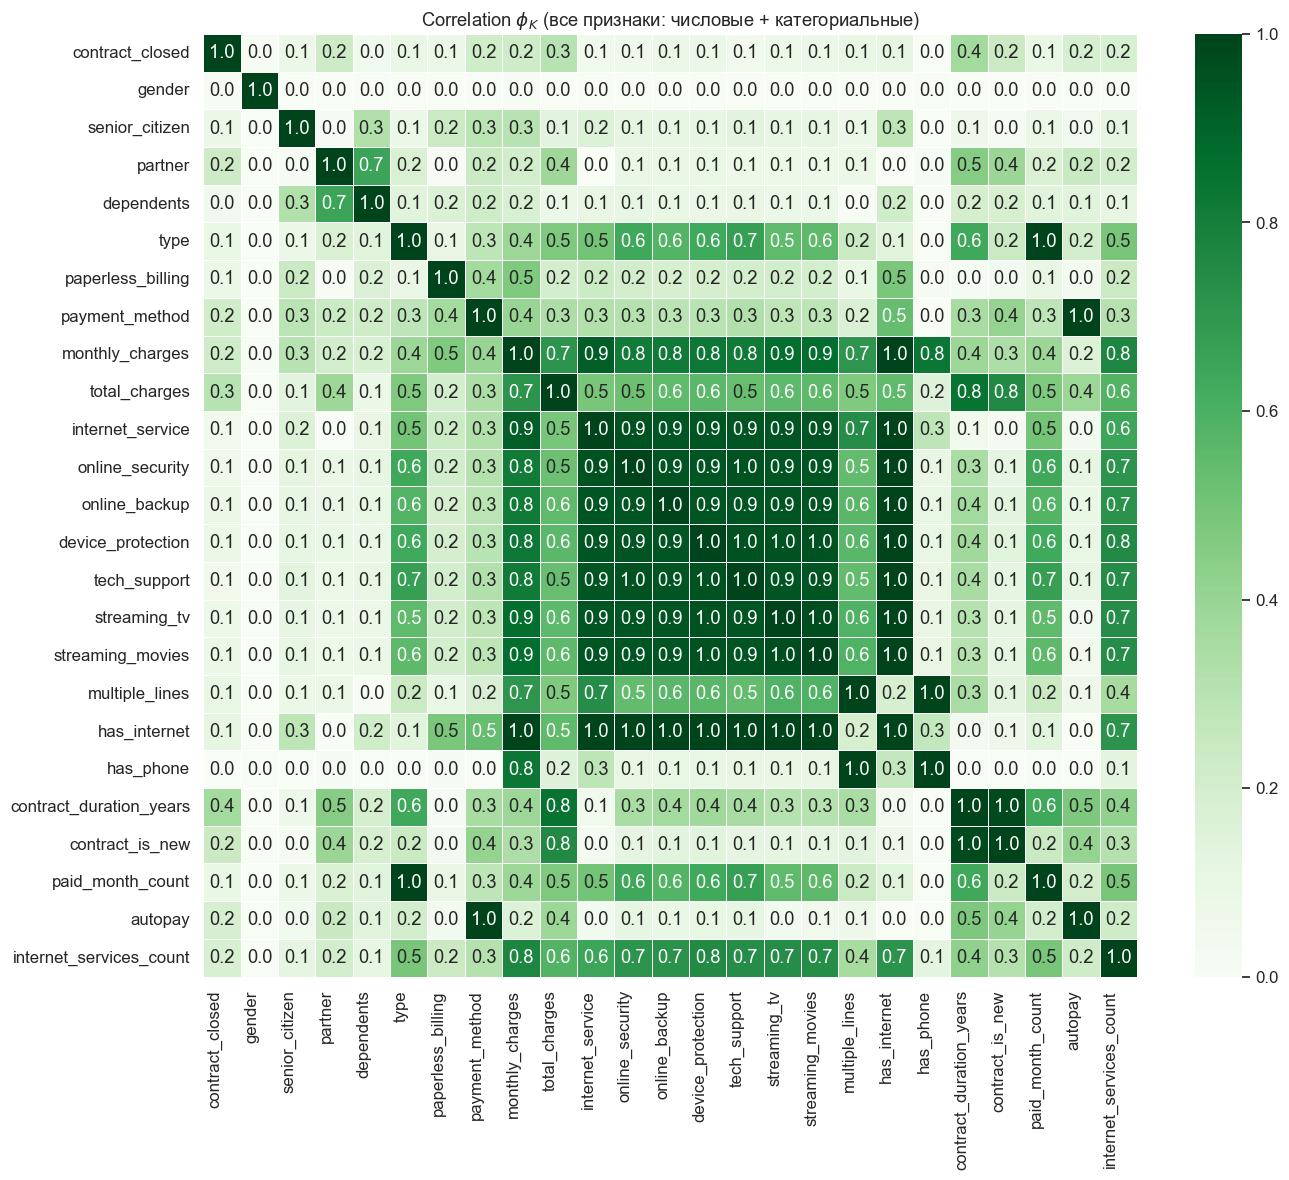

In [128]:
interval_cols = ['monthly_charges', 'total_charges', 'contract_duration_months', 'contract_duration_years', 'internet_services_count', 'paid_month_count']

phik_overview = phik.phik_matrix(data_all, interval_cols=interval_cols)

plt.figure(figsize=(14, 12))
sns.heatmap(
    phik_overview,
    annot=True,
    fmt=".1f",
    cmap='Greens',
    vmin=0, vmax=1,
    linewidths=.5
)
plt.title(r'Correlation $\phi_K$ (все признаки: числовые + категориальные)')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

Наблюдаем высокую мультиколлинеарность между признаками подключения дополнительных интернет-услуг. Построим матрицу без них. Оставим агрегирующий услуги признак internet_services_count.

Сразу уберем из визуализации признаки type и payment_method. Мы модернизировали их, новые версии не хуже коррелируют с таргетом.

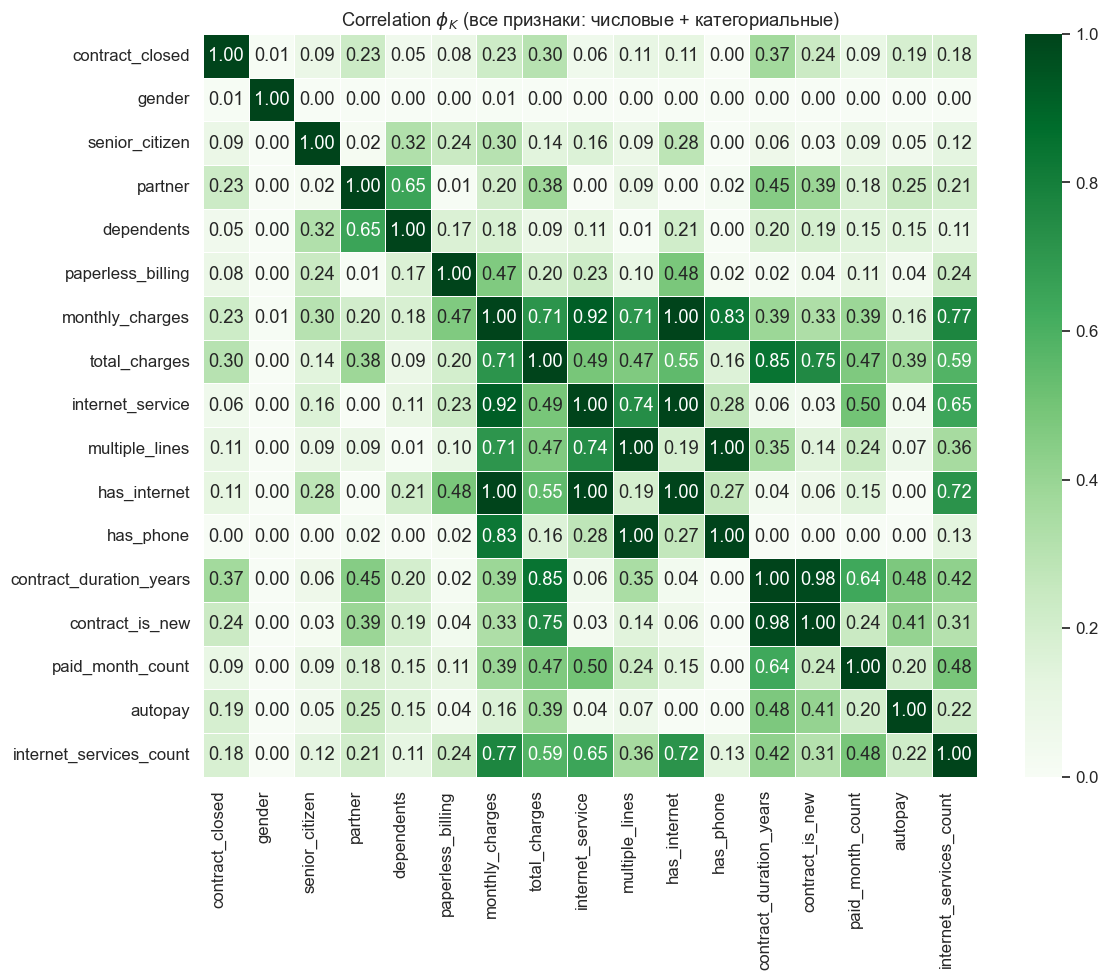

In [129]:
data_all_1 = data_all.drop(['online_security', 'online_backup',
                            'device_protection', 'tech_support',
                            'streaming_tv', 'streaming_movies',
                            'type', 'payment_method'], axis=1)

phik_overview = phik.phik_matrix(data_all_1, interval_cols=interval_cols)

plt.figure(figsize=(12, 10))
sns.heatmap(
    phik_overview,
    annot=True,
    fmt=".2f",
    cmap='Greens',
    vmin=0, vmax=1,
    linewidths=.5
)
plt.title(r'Correlation $\phi_K$ (все признаки: числовые + категориальные)')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

По итогу корреляционного анализа видим наличие мульколлинеарности между рядом признаков, а также слабую взаимосвязь ряда признаков с таргетом. 

При этом мы понимаем, что
- признаки могут влиять на таргет не по отдельности, а в совокупности - группой;
- моделям, которые мы будем пробовать, не страшна мультиколлинеарность.

### Подготовка выборок

Формирование X путем отбора признаков из data_all осуществлялось **с учетом результатов обучения моделей и анализа важности признаков для лучшей модели**. Также проводилась сверка с результатами корреляционного анализа и визуализация соотношений ушедших и оставшихся абонентов для признаков.

Забегая вперед, обозначим, что лучшей оказалась модель CatBoostClassifier с маленьким значением model__depth. Большое количество признаков оказалось для неё излишним.

**Логика удаления признаков была такая:**
1. type и payment_method удалены как исходники новых признаков paid_month_count и autopay.
2. Признак total_charges оказался важным для модели, как и monthly_charges, contract_duration_years. При этом общие расходы по договору по факту являются следствием длительности договора и месячных платежей. Мы можем оставить только информацию об актуальном размере платежа и более понятный, чем total_charges, признак длительность договора.
- При удалении total_charges качество работы модели улучшилось. Видимо, когда участвовали все 3 признака, модель с маленькой глубиной "зацикливалась" только на них и хуже учитывала другие признаки.

3. Прочие признаки были удалены как оказавшиеся незначительно важными для модели. Если свериться с матрицей корреляции выше, видим, что корреляция удаленных признаков с таргетом не превышает 0.1 (за исключением contract_is_new, но вместо него работает непрерывный признак contract_duration_years).

In [130]:
y = data_all['contract_closed']
X = data_all.drop(['contract_closed', 'type', 'payment_method',
                   'has_internet', 'has_phone', 'contract_is_new',
                   'gender', 'senior_citizen', 'dependents', 'paperless_billing', 'internet_service',
                   'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies',
                   'total_charges'], axis=1)

X.shape

(7032, 7)

Получили датасет всего лишь из 7 признаков.

Разделим данные на выборки.

In [131]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)

X_train.shape, X_test.shape

((5274, 7), (1758, 7))

In [132]:
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'int32']).columns.tolist()

numeric_features, categorical_features

(['monthly_charges',
  'contract_duration_years',
  'paid_month_count',
  'internet_services_count'],
 ['partner', 'multiple_lines', 'autopay'])

Создадим препроцессор для кодирования и масштабирования. Он подойдет для всех моделей, которые будем пробовать.

In [133]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), categorical_features)
    ],                                 
    remainder='passthrough'
)

## Обучение моделей
### Модели и параметры
Обучим модели 3 классов:
1. решающее дерево или случайный лес - **RandomForestClassifier**;
2. бустинги - **CatBoostClassifier**;
3. нейронные сети - **MLP**.

Для каждой модели подберем некоторы гиперпараметры.
   
Сравнивать модели будем по значению метрики **ROC-AUC** на кросс-валидации.

#### RandomForestClassifier

In [134]:
rf_clf = Pipeline(steps=[('preprocessor', preprocessor),
                         ('model', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))])

param_dist_rf = {
    'model__n_estimators': [300, 400],
    'model__max_depth': [None, 10],
    'model__min_samples_split': [5, 7]
}

#### CatBoostClassifier

In [135]:
cb_clf = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', CatBoostClassifier(
        random_state=RANDOM_STATE,
        verbose=0,
        allow_writing_files=False
    ))
])

param_dist_cb = {
    'model__depth': [3, 5],
    'model__learning_rate': [0.1, 0.15, 0.2],
    'model__l2_leaf_reg': [3, 4],
    'model__iterations': [450, 500, 550]
}

#### MLP (нейросеть)

In [136]:
mlp_clf = Pipeline(steps=[('preprocessor', preprocessor),
                          ('model', MLPClassifier(random_state=RANDOM_STATE))])

param_dist_mlp = {
    'model__hidden_layer_sizes': [(64, 32), (128, 64), (256, 128)],
    'model__alpha': [0.0001, 0.001],
    'model__early_stopping': [True],
    'model__validation_fraction': [0.15]
}

### Выбор модели

Подбирать гиперпараметры и выбирать лучшую модель будем одним запуском GridSearchCV.

**GridSearchCV** применен для лучшего качества подбора гиперпараметров. 

Для получения первых результатов был применен **RandomizedSearchCV** на большом разнообразии гиперпараметов. В процессе подбора лучшая метрика держалась на уровне не ниже 0.82.

Далее, чтобы достичь требуемого качества, важно было рассмотреть все комбинации гиперпараметров (без фактора случайности). Поэтому для нас оказалось удобным многокрвтно перезапустить подбор GridSearchCV, сужая и перемещая интервалы гиперпараметов в сторону лучшего значения.

In [137]:
models = [
    ('RandomForest', rf_clf, param_dist_rf),
    ('CatBoost', cb_clf, param_dist_cb),
    ('MLP', mlp_clf, param_dist_mlp)    
]

best_models = {}
best_scores = {}


In [138]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, model, param_dist in models:
    print(f"Подбор гиперпараметров для {name}...")
    search = GridSearchCV(
        model,
        param_grid=param_dist,
        scoring='roc_auc',
        cv=cv,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_
    display(f"{name} — ROC-AUC на CV: {search.best_score_:.3f}")
    display("Лучшие параметры:", search.best_params_)

best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]
display(f"\nЛучшая модель по значению метрики - {best_name}")

Подбор гиперпараметров для RandomForest...


'RandomForest — ROC-AUC на CV: 0.828'

'Лучшие параметры:'

{'model__max_depth': 10,
 'model__min_samples_split': 7,
 'model__n_estimators': 300}

Подбор гиперпараметров для CatBoost...


...

Подбор гиперпараметров для MLP...


'MLP — ROC-AUC на CV: 0.825'

'Лучшие параметры:'

{'model__alpha': 0.001,
 'model__early_stopping': True,
 'model__hidden_layer_sizes': (128, 64),
 'model__validation_fraction': 0.15}

'\nЛучшая модель по значению метрики - CatBoost'

Выведем рейтинг важности признаков для лучшей модели, чтобы попробовать отказаться от наименее важных.

In [139]:
prep = best_model.named_steps['preprocessor']
bm = best_model.named_steps['model']

X_t = prep.transform(X_train)
X_t = np.asarray(X_t)

imp = bm.get_feature_importance(Pool(X_t, y_train))

feature_map = []
current_idx = 0

for name, trans, cols in prep.transformers_:
    
    cols_list = [cols] if isinstance(cols, str) else list(cols)

    if hasattr(trans, 'get_feature_names_out'):
        names = trans.get_feature_names_out(cols_list)
        for i, n in enumerate(names):
            feature_map.append((current_idx + i, n))
        current_idx += len(names)
    else:
        for i, col in enumerate(cols_list):
            feature_map.append((current_idx + i, col))
        current_idx += len(cols_list)

df_imp = pd.DataFrame(feature_map, columns=['index', 'feature'])
df_imp['importance'] = round(df_imp['index'].map(lambda i: imp[i]), 2)

df_imp.sort_values('importance', ascending=False)[['feature', 'importance']]

,feature,importance
1,contract_duration_years,55.68
0,monthly_charges,18.43
2,paid_month_count,8.58
3,internet_services_count,7.08
6,multiple_lines_Yes,3.30
4,partner_Yes,2.91
7,autopay_1,2.65
5,multiple_lines_No,1.38


Были исключены признаки, имевшие важность сначала менее 1.0, затем и менее 1.5.

Как видим наиболее влиящий на решение модели признак - длительность контракта. Также важна сумма месячных расходов.

## Тестирование модели

In [140]:
y_pred_proba = best_model.predict_proba(X_test)[:, 1]
y_pred = best_model.predict(X_test)

roc_auc = roc_auc_score(y_test, y_pred_proba)
acc = accuracy_score(y_test, y_pred)
display(f"ROC-AUC на тестовой выборке: {roc_auc:.3f}")
display(f"Accuracy на тестовой выборке: {acc:.3f}")

'ROC-AUC на тестовой выборке: 0.853'

'Accuracy на тестовой выборке: 0.882'

**Требование ROC-AUC на тестовой выборке не менее 0.85 выполнено.**

Построим матрицу ошибок модели, рассчитаем полноту и точность.

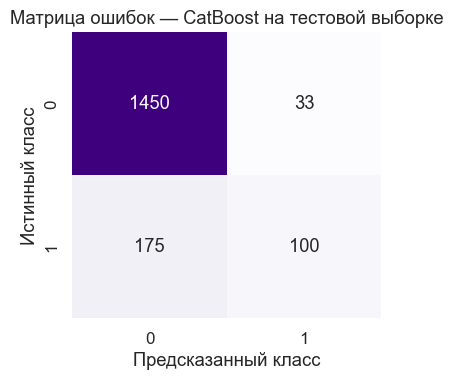

In [141]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(4, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.title(f'Матрица ошибок — {best_name} на тестовой выборке')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

In [142]:
display(f"precision = {round(100/133, 2)}")
display(f"recall = {round(100/275, 2)}")

'precision = 0.75'

'recall = 0.36'

Из всех ушедших абонентов модель смогла предсказать лишь 36%.

Зато среди предсказанных расторжений 75% действительно состоялись. **Хорошее значение precision позволит компании минимально предлагать скидки и промокоды абонентам, которые уходить не планируют.**

Отобразим полноту и точность модели на графике.

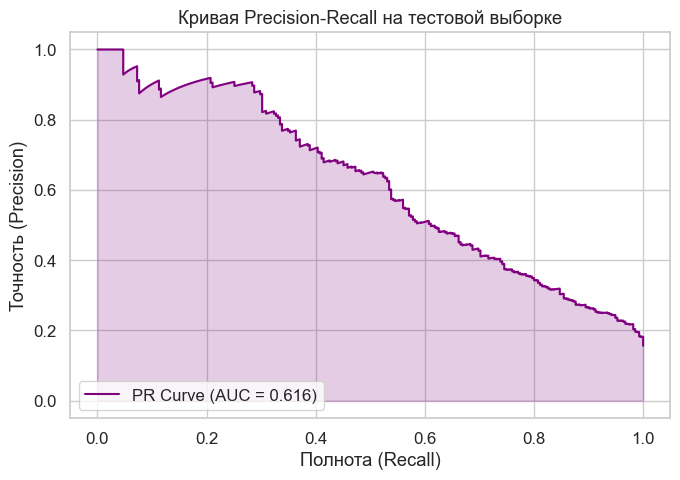

In [143]:
prec, rec, thresholds = precision_recall_curve(y_test, y_pred_proba)
pr_auc = auc(rec, prec)

plt.figure(figsize=(7, 5))
plt.plot(rec, prec, label=f'PR Curve (AUC = {pr_auc:.3f})', color='purple')
plt.fill_between(rec, prec, alpha=0.2, color='purple')
plt.xlabel('Полнота (Recall)')
plt.ylabel('Точность (Precision)')
plt.title('Кривая Precision-Recall на тестовой выборке')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

Площадь под кривой 0.616 говорит о не слишком высоком общем качестве модели.

Заказчик должен понимать, что в текущей версии модель предсказывает далеко не всех абонентов, которые планируют уйти.

**Для повышения recall изменением порога предсказания придется пожертвовать значением precision.**


Оценим важность признаков на тестовой выборке.

In [144]:
X_t_test = prep.transform(X_test)
X_t_test = np.asarray(X_t_test)

imp = bm.get_feature_importance(Pool(X_t_test, y_test))

feature_map = []
current_idx = 0

for name, trans, cols in prep.transformers_:
    
    cols_list = [cols] if isinstance(cols, str) else list(cols)

    if hasattr(trans, 'get_feature_names_out'):
        names = trans.get_feature_names_out(cols_list)
        for i, n in enumerate(names):
            feature_map.append((current_idx + i, n))
        current_idx += len(names)
    else:
        for i, col in enumerate(cols_list):
            feature_map.append((current_idx + i, col))
        current_idx += len(cols_list)

df_imp = pd.DataFrame(feature_map, columns=['index', 'feature'])
df_imp['importance'] = round(df_imp['index'].map(lambda i: imp[i]), 2)

df_imp.sort_values('importance', ascending=False)[['feature', 'importance']]

,feature,importance
1,contract_duration_years,54.15
0,monthly_charges,19.30
2,paid_month_count,8.57
3,internet_services_count,7.38
6,multiple_lines_Yes,3.46
4,partner_Yes,3.06
7,autopay_1,2.62
5,multiple_lines_No,1.47


"Рейтинг" признаков тот же, что и на обучающей выборке.

Построим график **зависимости таргета от длительности договора в годах**.

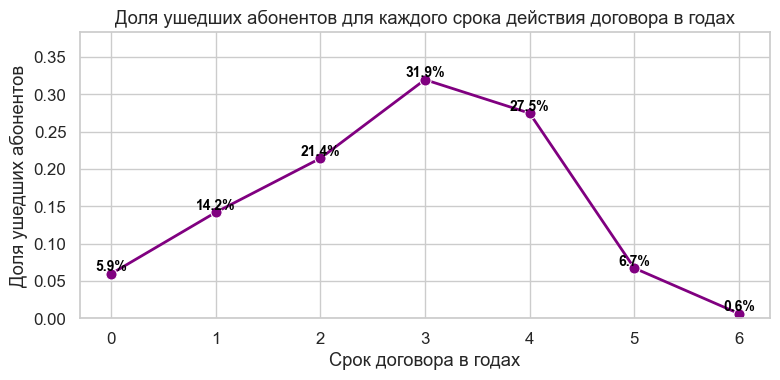

In [145]:
agg = (X_test.assign(closed=y_test)
              .assign(year=lambda x: x['contract_duration_years'].round().astype(int))
              .groupby('year')
              .agg(count=('closed', 'size'), closed_share=('closed', 'mean'))
              .reset_index())

plt.figure(figsize=(8, 4))
ax = sns.lineplot(data=agg, x='year', y='closed_share', marker='o', linewidth=2, markersize=8, color='purple')

for i, row in agg.iterrows():
    pct = row['closed_share'] * 100
    ax.text(row['year'], row['closed_share'], f'{pct:.1f}%', ha='center', va='bottom', fontsize=10, color='black', weight='bold')

plt.xlabel('Срок договора в годах')
plt.ylabel('Доля ушедших абонентов')
plt.title('Доля ушедших абонентов для каждого срока действия договора в годах')
plt.xticks(agg['year'])
plt.ylim(0, max(agg['closed_share']) * 1.2)
plt.tight_layout()
plt.show()

Опасность ухода абоннта увеличивается и достигает максимума к сроку договора 3 года. После 3-4 лет вероятность расторжения договора снижается.

## Вывод

Полученные для работы таблицы содержали всю обозначенную информацию. Объем данных в таблицах оказался  небольшим. 	

In [146]:
pd.read_sql_query(query_counts, con=engine)

,table_name,row_count
0,contract,7043
1,personal,7043
2,internet,5517
3,phone,6361


Дубликаты и пропуски не выявлены.

В ходе исследовательского анализа и предварительной обработки данных были **внесены следующие изменения**:
- столбцы с датами и информацией о суммах раходов были приведены к корректным типам данных,
- удалены 11 строк, содержащих информацию об абонентах, заключивших договоры в день выгрузки данных,
- данные были объединены в общий датафрейм по id абонента.

Были созданы **дополнительные признаки**:
- бинарные признаки 0/1, обозначающие наличие телефона и интернета,
- длительность договоров в годах до даты закрытия или до даты выгрузки данных по открытым договорам,
- бинарный признак 0/1 - договор длительностью до полугода,
- количество оплачиваемых за раз месяцев - 1/12/24,
- наличие автоплатежа,
- количество подключенных дополнительных интернет-услуг из 6 возможных.

По результату исследователького анализа, корреляционного анализа, обучения моделей и анализа важности признаков для лучшей модели были отобраны 7 полезных признаков.

Были обучены смодели 3 классов:
1. решающее дерево или случайный лес - **RandomForestClassifier**;
2. бустинги - **CatBoostClassifier**;
3. нейронные сети - **MLP**.
   
Для каждой модели подбирались гиперпараметры.
   
Сравнение моделей осуществлялось по значению метрики **ROC-AUC** на кросс-валидации.

Лучшее значение метрики показла модель **CatBoostClassifier - ROC-AUC на кросс-валидации = 0.867**.

Модель была оценена **на тестовой выборке - получено значение ROC-AUC = 0.853**.

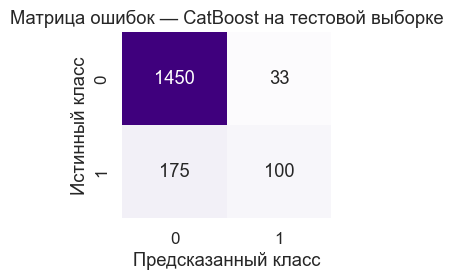

In [149]:
plt.figure(figsize=(3, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False)
plt.title(f'Матрица ошибок — {best_name} на тестовой выборке')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.tight_layout()
plt.show()

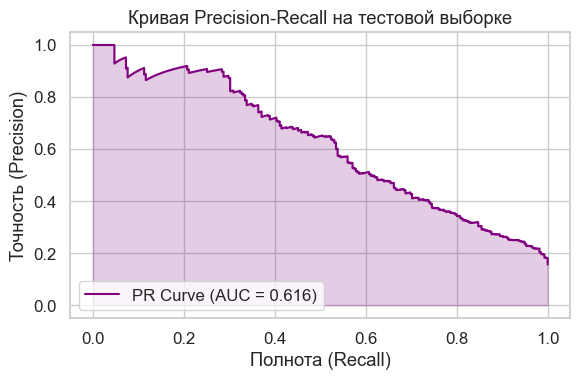

In [152]:
plt.figure(figsize=(6, 4))
plt.plot(rec, prec, label=f'PR Curve (AUC = {pr_auc:.3f})', color='purple')
plt.fill_between(rec, prec, alpha=0.2, color='purple')
plt.xlabel('Полнота (Recall)')
plt.ylabel('Точность (Precision)')
plt.title('Кривая Precision-Recall на тестовой выборке')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()

Precision = 0.75

Recall = 0.36

Из всех ушедших абонентов модель смогла предсказать лишь 36%. Зато среди предсказанных расторжений 75% действительно состоялись. **Хорошее значение precision позволит компании минимально предлагать специальные условия и промокоды абонентам, которые уходить не планируют.**

При этом площадь под кривой Precision-Recall 0.616 говорит о не слишком высоком общем качестве модели.

Заказчик должен понимать, что в текущей версии модель предсказывает далеко не всех абонентов, которые планируют уйти.

**Если для компании важно найти максимальное количество абонентов под риском ухода, то для повышения recall изменением порога предсказания придется пожертвовать значением precision и предложить промокоды и специальные условия тем абонентам, которые уходить не планировали.**

**Рейтинг важности признаков для модели** (значения важности, расчитаные на тестовой выборке):

In [153]:
df_imp.sort_values('importance', ascending=False)[['feature', 'importance']]

,feature,importance
1,contract_duration_years,54.15
0,monthly_charges,19.30
2,paid_month_count,8.57
3,internet_services_count,7.38
6,multiple_lines_Yes,3.46
4,partner_Yes,3.06
7,autopay_1,2.62
5,multiple_lines_No,1.47


**Наиболее существенное влияние на прогноз модели оказывает:**
1. **Длительность договора**. Опасность ухода абонента увеличивается и достигает максимума к сроку договора 3 года. После 3-4 лет вероятность расторжения договора снижается.

**В ТОП-4 признаков (с наиболее существенной важностью) также входят:**

2. Месячные расходы абонента на связь (большие расходы ассоциируются с большей вероятностью ухода абонента - см. п. 2.8.2). Те, кто платит мало, уходят редко - вероятно, это пользователи только телефонной связи.
3. Количество оплачиваемых за раз месяцев - 1, 12 или 24 (те, кто платит помесячно, уходили реже - см.п. 2.8.1).
4. Количество подключенных интернет-услуг из 6 доступных (абоненты, использующие дополнительные услуги уходят чаще - см.п. 2.8.1).